# Laboratorio 3 — La tarea de clasificación
## Caso Ruta Alpes: predicción de aceptación de cupones

**Curso:** ISIS-2611 Aprendizaje Automático · **Periodo:** 202620

**Integrantes:** Juan Manuel Rodríguez Díaz (202013372) — Nikol Katherin Rodríguez Ortiz (202317538)

---

### Contexto

Ruta Alpes es una aplicación de asistencia de conducción que envía recomendaciones personalizadas de
cupones a los conductores mientras se desplazan. Enviar la misma oferta a todos genera baja
efectividad y, en algunos casos, molestia por notificaciones irrelevantes. La empresa recopiló
escenarios reales de conducción junto con características demográficas y hábitos de consumo, y nos
contrata para determinar **cuándo un conductor tiene mayor probabilidad de aceptar un cupón**,
trabajando sobre dos tipos: **Cafetería** y **Restaurante(<20)**.

Además de la predicción, Ruta Alpes quiere evaluar los **riesgos de sesgo y las implicaciones éticas**
de personalizar ofertas usando datos demográficos.

### Objetivos

1. Comparar regresión logística, árboles de decisión y Random Forest para cada tipo de cupón.
2. Evaluar si el desbalance de clases afecta el desempeño y si una técnica de balanceo lo mejora.
3. Reconocer posibles sesgos, en particular los derivados del uso de variables demográficas.
4. Comunicar los resultados sustentando las decisiones metodológicas.

### Decisiones metodológicas que el enunciado deja abiertas

El enunciado no fija la partición ni la métrica de optimización, así que las declaramos aquí de forma
explícita y las mantenemos constantes en todo el laboratorio:

| Decisión | Valor | Justificación |
|:---|:---|:---|
| Partición entrenamiento/prueba | 75 % / 25 % | Consistencia con el laboratorio 1 del curso |
| `random_state` | 42 | Reproducibilidad; mismo valor usado en el curso |
| Estratificación | por `acepta_cupon` | Restaurante(<20) está desbalanceado; sin estratificar, la proporción de clases variaría entre particiones |
| Métrica de `GridSearchCV` | `f1` | Es la métrica con la que se califica la actividad 11 y la adecuada ante desbalance |
| Validación cruzada | `StratifiedKFold(5)` | Preserva la proporción de clases en cada pliegue |
| Clase positiva | `Sí` (acepta) | La pregunta de negocio es *cuándo acepta* un conductor |

> **Nota sobre la clase minoritaria.** En Restaurante(<20) el 70,7 % de los casos son `Sí`, de modo que
> **la clase minoritaria es `No`**. Cuando la actividad 6 pide "el recall de la clase minoritaria", se
> refiere al recall de `No`. Lo reportamos de forma separada y etiquetado para que no haya ambigüedad.

### Contenido

1. [Carga de datos y diccionario](#s1)
2. [Exploración de los datos](#s2)
3. [Limpieza y preparación](#s3)
4. [Modelos de regresión logística](#s4)
5. [Modelos de árbol de decisión](#s5)
6. [Modelos de Random Forest](#s6)
7. [Evaluación del balanceo de clases en Restaurante(<20)](#s7)
8. [Tabla comparativa y selección del mejor modelo](#s8)
9. [Identificación de las variables más relevantes](#s9)
10. [Análisis de resultados](#s10)
11. [Predicciones sobre los datos no etiquetados](#s11)
12. [Uso de herramientas de IA generativa](#s12)

In [1]:
# ============================================================
# Configuración del entorno
# ============================================================
import warnings, os, time
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate
from sklearn.metrics import (recall_score, precision_score, f1_score, accuracy_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve)
from sklearn.inspection import permutation_importance

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
                     'figure.autolayout': True})
pd.set_option('display.width', 180, 'display.max_columns', 60)

# --- Decisiones metodológicas declaradas en la portada ---
RANDOM_STATE = 42
TEST_SIZE    = 0.25
SCORING      = 'f1'
CV           = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
# Paralelismo: se serializa el nivel externo (GridSearchCV, cross_validate,
# permutation_importance) y se paraleliza el estimador interno (Random Forest, que escala
# muy bien). Anidar ambos niveles sobresuscribe los núcleos, agota la memoria y hace que
# joblib mate los workers con un TerminatedWorkerError.
N_JOBS       = 1
CUPONES      = ['Cafetería', 'Restaurante(<20)']
np.random.seed(RANDOM_STATE)

import sklearn, imblearn
print('pandas', pd.__version__, '| scikit-learn', sklearn.__version__,
      '| imbalanced-learn', imblearn.__version__)

pandas 3.0.1 | scikit-learn 1.8.0 | imbalanced-learn 0.14.1


<a name="s1"></a>
## 1. Carga de datos y diccionario

| Archivo | Contenido |
|:---|:---|
| `Lab3_Datos.xlsx` | Datos **etiquetados** (contienen `acepta_cupon`), con los 5 tipos de cupón |
| `Lab3_datos_Prueba.xlsx` | Datos **no etiquetados** sobre los que hay que entregar la predicción |
| `Lab3_diccionario_Datos.xlsx` | Definición de las 26 variables, con el **orden de las ordinales** |

El diccionario no es un trámite: declara explícitamente el orden de las nueve variables ordinales
(`edad`, `educacion`, `ingreso`, `hora` y las cinco de frecuencia). Ese orden es lo que nos permite
codificarlas preservando su significado en lugar de tratarlas como categorías sin relación.

In [2]:
# Los archivos .xlsx pueden estar en una subcarpeta 'data' o junto al notebook.
DATA = 'data' if os.path.isfile(os.path.join('data', 'Lab3_Datos.xlsx')) else '.'
print(f'Leyendo los datos desde: {os.path.abspath(DATA)}')
etiquetado_raw = pd.read_excel(os.path.join(DATA, 'Lab3_Datos.xlsx'))
prueba_raw     = pd.read_excel(os.path.join(DATA, 'Lab3_datos_Prueba.xlsx'))
diccionario    = pd.read_excel(os.path.join(DATA, 'Lab3_diccionario_Datos.xlsx'))

print(f'Conjunto etiquetado : {etiquetado_raw.shape[0]:,} filas x {etiquetado_raw.shape[1]} columnas')
print(f'Conjunto de prueba  : {prueba_raw.shape[0]:,} filas x {prueba_raw.shape[1]} columnas')
print(f'Columna presente solo en el etiquetado: {set(etiquetado_raw.columns) - set(prueba_raw.columns)}')
print(f'\nCoherencia diccionario <-> datos:')
print(f'  variables del diccionario ausentes en los datos: '
      f'{set(diccionario.iloc[:,0]) - set(etiquetado_raw.columns) or "ninguna"}')
print(f'  columnas de los datos ausentes del diccionario  : '
      f'{set(etiquetado_raw.columns) - set(diccionario.iloc[:,0]) or "ninguna"}')

Leyendo los datos desde: C:\Users\azrae\Downloads


Conjunto etiquetado : 12,664 filas x 26 columnas
Conjunto de prueba  : 20 filas x 25 columnas
Columna presente solo en el etiquetado: {'acepta_cupon'}

Coherencia diccionario <-> datos:
  variables del diccionario ausentes en los datos: ninguna
  columnas de los datos ausentes del diccionario  : ninguna


In [3]:
pd.set_option('display.max_colwidth', 150)
diccionario

,Variable,Tipo,Descripción
0,destino,Categórica nominal,"Destino del trayecto en el momento en que se ofrece el cupón. Valores posibles: Casa, Sin lugar urgente, Trabajo."
1,acompanante,Categórica nominal,"Tipo de acompañante(s) en el vehículo al momento de la oferta. Valores posibles: Solo, Amigo(s), Hijo(s), Pareja."
2,clima,Categórica nominal,"Condición climática durante el trayecto. Valores posibles: Soleado, Lluvioso, Nevado."
3,temperatura,Numérica entero,"Temperatura ambiente en grados Fahrenheit. Variable de diseño de la encuesta: solo toma 3 valores fijos, asociados al clima. Rango: {30, 55, 80}."
4,hora,Categórica ordinal,"Hora del día en que ocurre el trayecto. Valores posibles (en orden): 7:00 a.m., 10:00 a.m., 2:00 p.m., 6:00 p.m., 10:00 p.m."
5,cupon,Categórica nominal,"Tipo de cupón ofrecido al conductor. Valores posibles: Bar, Cafetería, Comida para llevar, Restaurante(<20), Restaurante(20-50). Los valores <20 y..."
6,vigencia_cupon,Categórica nominal,"Tiempo de vigencia del cupón antes de expirar. Valores posibles: 2 horas, 1 día."
7,genero,Categórica nominal,"Género reportado por el conductor. Valores posibles: Femenino, Masculino."
8,edad,Categórica ordinal,"Rango de edad del conductor. Valores posibles (en orden): menor de 21, 21, 26, 31, 36, 41, 46, 50 o más."
9,estado_civil,Categórica nominal,"Estado civil del conductor. Valores posibles: Soltero(a), Casado(a), Unión libre, Divorciado(a), Viudo(a)."


In [4]:
pd.set_option('display.max_colwidth', 40)
etiquetado_raw.head()

,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,tiene_hijos,educacion,ocupacion,ingreso,vehiculo,frecuencia_bar,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
0,Sin lugar urgente,Solo,Soleado,55,2:00 p.m.,Restaurante(<20),1 día,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,Sí
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,No
2,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Comida para llevar,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,Sí
3,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No
4,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,1 día,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No


<a name="s2"></a>
## 2. Exploración de los datos

Numeramos cada hallazgo (**H1 … H9**) y lo retomamos explícitamente en la sección de preparación.

### 2.1 Estructura, tipos y valores ausentes

In [5]:
resumen = pd.DataFrame({
    'tipo'     : etiquetado_raw.dtypes.astype(str),
    'nulos'    : etiquetado_raw.isna().sum(),
    '%_nulos'  : (etiquetado_raw.isna().mean()*100).round(2),
    'unicos'   : etiquetado_raw.nunique(),
})
resumen['valores'] = [
    ', '.join(sorted(map(str, etiquetado_raw[c].dropna().unique()))[:4]) +
    ('...' if etiquetado_raw[c].nunique() > 4 else '')
    for c in etiquetado_raw.columns]
resumen

,tipo,nulos,%_nulos,unicos,valores
destino,str,0,0.00,3,"Casa, Sin lugar urgente, Trabajo"
acompanante,str,0,0.00,4,"Amigo(s), Hijo(s), Pareja, Solo"
clima,str,0,0.00,3,"Lluvioso, Nevado, Soleado"
temperatura,int64,0,0.00,3,"30, 55, 80"
hora,str,0,0.00,5,"10:00 a.m., 10:00 p.m., 2:00 p.m., 6..."
cupon,str,0,0.00,5,"Bar, Cafetería, Comida para llevar, ..."
vigencia_cupon,str,0,0.00,2,"1 día, 2 horas"
genero,str,0,0.00,2,"Femenino, Masculino"
edad,str,0,0.00,8,"21, 26, 31, 36..."
estado_civil,str,0,0.00,5,"Casado(a), Divorciado(a), Soltero(a)..."


> **H1 — `vehiculo` es inutilizable.** Tiene **99,15 % de valores ausentes** en el conjunto etiquetado
> (12 556 de 12 664 filas) y **100 % en el conjunto de prueba**. No se puede imputar de forma sensata
> con 108 observaciones, y aunque se pudiera, no habría ningún valor en prueba sobre el que aplicarla.
> Se elimina.
>
> **H2 — `tiempo_cupon_mayor_5min` es constante.** Toma el valor `Sí` en las 12 664 filas. Una variable
> sin varianza no aporta información a ningún modelo: los árboles no pueden partir por ella y en la
> regresión logística su coeficiente es indeterminado. Se elimina.
>
> **H3 — Ausencias leves en las cinco variables de frecuencia.** Entre 0,84 % y 1,71 %
> (107–217 filas). Son categóricas ordinales, así que se imputan con la moda dentro del `Pipeline`.
> El volumen es bajo y el patrón disperso, de modo que el efecto sobre el modelo es menor.

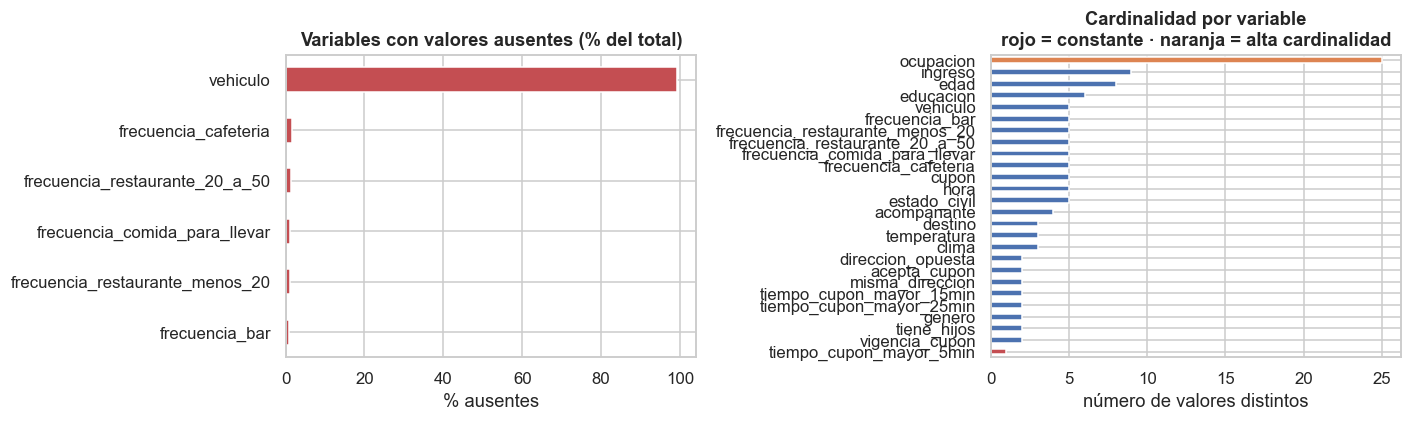

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
nulos = (etiquetado_raw.isna().mean()*100)
nulos[nulos > 0].sort_values().plot.barh(ax=ax[0], color='#c44e52')
ax[0].set_title('Variables con valores ausentes (% del total)'); ax[0].set_xlabel('% ausentes')

card = etiquetado_raw.nunique().sort_values()
colores = ['#c44e52' if v <= 1 else ('#dd8452' if v > 20 else '#4c72b0') for v in card]
card.plot.barh(ax=ax[1], color=colores)
ax[1].set_title('Cardinalidad por variable\nrojo = constante · naranja = alta cardinalidad')
ax[1].set_xlabel('número de valores distintos')
plt.show()

### 2.2 Registros duplicados y etiquetas contradictorias

In [7]:
features = [c for c in etiquetado_raw.columns if c != 'acepta_cupon']

print(f'Filas exactamente duplicadas (incluida la etiqueta) : {etiquetado_raw.duplicated().sum()}')
print(f'Filas duplicadas ignorando la etiqueta              : '
      f'{etiquetado_raw[features].duplicated().sum()}')

# Combinaciones idénticas de variables con etiqueta distinta
grupos = etiquetado_raw.groupby(features, dropna=False)['acepta_cupon'].nunique()
contradictorias = (grupos > 1).sum()
print(f'Combinaciones de variables con etiquetas CONTRADICTORIAS : {contradictorias}')

afectadas = etiquetado_raw[etiquetado_raw[features].duplicated(keep=False)]
print(f'\nFilas involucradas en alguna repetición de variables: {len(afectadas)}')
afectadas.sort_values(features).head(6)[['destino','acompanante','clima','hora','cupon',
                                          'genero','edad','acepta_cupon']]

Filas exactamente duplicadas (incluida la etiqueta) : 74
Filas duplicadas ignorando la etiqueta              : 97
Combinaciones de variables con etiquetas CONTRADICTORIAS : 23

Filas involucradas en alguna repetición de variables: 194


,destino,acompanante,clima,hora,cupon,genero,edad,acepta_cupon
7396,Casa,Pareja,Soleado,10:00 p.m.,Comida para llevar,Masculino,46,Sí
8497,Casa,Pareja,Soleado,10:00 p.m.,Comida para llevar,Masculino,46,Sí
6955,Casa,Pareja,Soleado,6:00 p.m.,Cafetería,Femenino,31,Sí
7840,Casa,Pareja,Soleado,6:00 p.m.,Cafetería,Femenino,31,Sí
6954,Casa,Solo,Nevado,10:00 p.m.,Restaurante(20-50),Femenino,31,No
7839,Casa,Solo,Nevado,10:00 p.m.,Restaurante(20-50),Femenino,31,No


> **H4 — Duplicados de dos clases.** Hay **74 filas exactamente duplicadas**, que se eliminan sin
> pérdida de información. Pero además hay **97 filas con variables idénticas**, y en **23
> combinaciones la etiqueta es contradictoria**: el mismo escenario y el mismo perfil de conductor
> aparecen una vez como `Sí` y otra como `No`.
>
> Esas 23 no son un error que podamos corregir, y **eliminarlas sería peor que dejarlas**: representan
> algo real del fenómeno, que dos conductores idénticos ante el mismo escenario pueden decidir
> distinto. Lo que sí hacen es **fijar un techo al desempeño alcanzable**: ningún modelo determinista
> puede acertar en ambas. Lo tenemos en cuenta al interpretar las métricas, en lugar de buscar un F1
> cercano a 1 que sería señal de sobreajuste.

### 2.3 Distribución de la variable objetivo

In [8]:
print('Distribución global de acepta_cupon:')
print(etiquetado_raw.acepta_cupon.value_counts().to_string())

tabla = pd.crosstab(etiquetado_raw.cupon, etiquetado_raw.acepta_cupon)
tabla['total'] = tabla.sum(axis=1)
tabla['% Sí']  = (tabla['Sí'] / tabla.total * 100).round(2)
tabla['clase minoritaria'] = np.where(tabla['Sí'] < tabla['No'], 'Sí', 'No')
tabla['en el alcance'] = np.where(tabla.index.isin(CUPONES), '  <== SÍ', '')
print('\nDistribución por tipo de cupón:')
display(tabla.sort_values('% Sí'))

print(f'Filas utilizables (solo los dos cupones del alcance): '
      f'{tabla.loc[CUPONES, "total"].sum():,} de {len(etiquetado_raw):,} '
      f'({tabla.loc[CUPONES, "total"].sum()/len(etiquetado_raw)*100:.1f} %)')
print(f'\nConjunto de prueba por cupón:')
print(prueba_raw.cupon.value_counts().to_string())

Distribución global de acepta_cupon:
acepta_cupon
Sí    7196
No    5468

Distribución por tipo de cupón:


acepta_cupon,No,Sí,total,% Sí,clase minoritaria,en el alcance
cupon,,,,,,
Bar,1190,827,2017,41.00,Sí,
Restaurante(20-50),834,658,1492,44.10,Sí,
Cafetería,1997,1989,3986,49.90,Sí,<== SÍ
Restaurante(<20),814,1962,2776,70.68,No,<== SÍ
Comida para llevar,633,1760,2393,73.55,No,


Filas utilizables (solo los dos cupones del alcance): 6,762 de 12,664 (53.4 %)

Conjunto de prueba por cupón:
cupon
Cafetería           10
Restaurante(<20)    10


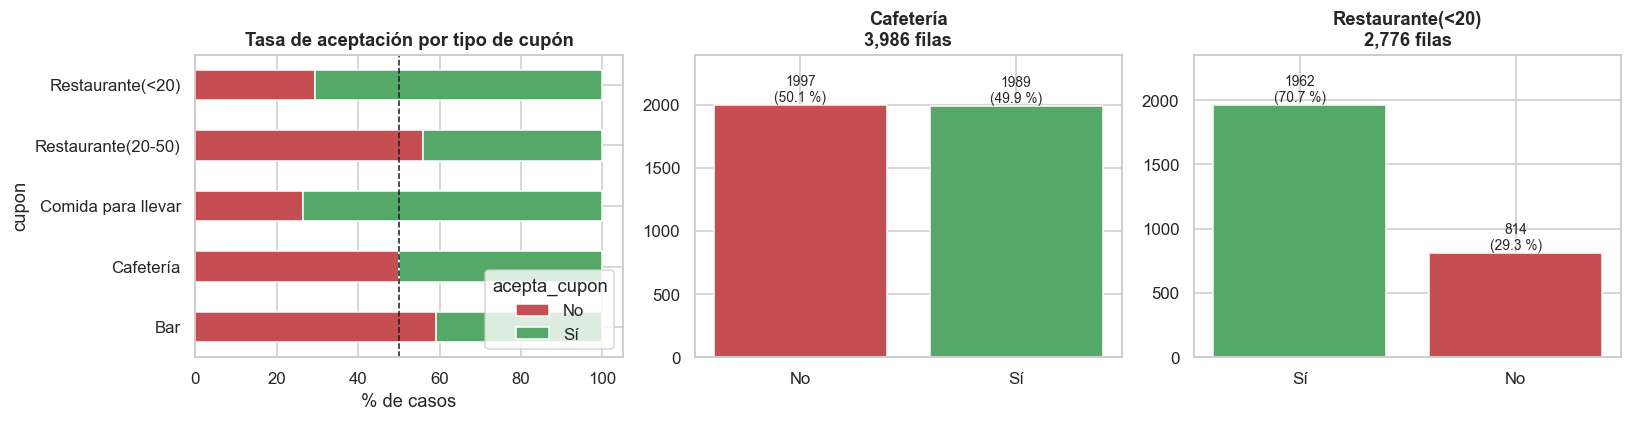

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

t = pd.crosstab(etiquetado_raw.cupon, etiquetado_raw.acepta_cupon, normalize='index')*100
t.loc[t.index.sort_values()].plot.barh(stacked=True, ax=ax[0], color=['#c44e52', '#55a868'])
ax[0].axvline(50, color='k', ls='--', lw=1)
ax[0].set_title('Tasa de aceptación por tipo de cupón'); ax[0].set_xlabel('% de casos')
ax[0].legend(title='acepta_cupon', loc='lower right')

for i, cup in enumerate(CUPONES, start=1):
    sub = etiquetado_raw[etiquetado_raw.cupon == cup]
    vc = sub.acepta_cupon.value_counts()
    ax[i].bar(vc.index, vc.values, color=['#55a868' if v == 'Sí' else '#c44e52' for v in vc.index])
    for j, v in enumerate(vc.values):
        ax[i].text(j, v, f'{v}\n({v/len(sub)*100:.1f} %)', ha='center', va='bottom', fontsize=9)
    ax[i].set_title(f'{cup}\n{len(sub):,} filas')
    ax[i].set_ylim(0, vc.max()*1.2)
plt.show()

> **H5 — El desbalance es muy distinto entre los dos cupones, y eso condiciona todo el laboratorio.**
>
> | Cupón | No | Sí | % Sí | Clase minoritaria |
> |:---|---:|---:|---:|:---|
> | Cafetería | 1 997 | 1 989 | **49,90 %** | prácticamente ninguna |
> | Restaurante(<20) | 814 | 1 962 | **70,68 %** | **`No`** |
>
> * **Cafetería está esencialmente balanceado** (1 989 frente a 1 997). Aquí no hay problema de
>   desbalance que corregir, y por eso el enunciado pide la evaluación de SMOTE solo para el otro
>   cupón.
> * **Restaurante(<20) tiene una proporción 71/29**, y **la clase minoritaria es `No`**. Esto tiene una
>   consecuencia práctica inmediata: un clasificador que respondiera siempre `Sí` obtendría un
>   F1 sobre la clase `Sí` de 0,83 sin haber aprendido nada. Por eso el F1 de la clase positiva, por sí
>   solo, es engañoso en este cupón, y hay que acompañarlo del recall de `No`.
>
> Para contexto: de los cinco tipos de cupón, Comida para llevar (73,6 %) y Restaurante(<20) (70,7 %)
> se aceptan mucho; Bar (41,0 %) y Restaurante(20-50) (44,1 %) se rechazan más. La hipótesis natural
> es que el **costo y el compromiso** que implica cada oferta explican la diferencia.

### 2.4 Variables redundantes o poco informativas

Esta subsección responde directamente a la segunda pregunta del análisis de resultados. En lugar de
conjeturar, verificamos cada sospecha con tablas de contingencia.

In [10]:
print('--- Redundancia 1: misma_direccion vs direccion_opuesta ---')
ct = pd.crosstab(etiquetado_raw.misma_direccion, etiquetado_raw.direccion_opuesta)
display(ct)
print(f'¿Son complementos exactos (nunca coinciden)? '
      f'{bool((etiquetado_raw.misma_direccion != etiquetado_raw.direccion_opuesta).all())}')
print(f'Correlación entre ambas (codificadas 0/1): '
      f'{etiquetado_raw.misma_direccion.eq("Sí").astype(int).corr(etiquetado_raw.direccion_opuesta.eq("Sí").astype(int)):.4f}')

--- Redundancia 1: misma_direccion vs direccion_opuesta ---


direccion_opuesta,No,Sí
misma_direccion,,
No,0,9944
Sí,2720,0


¿Son complementos exactos (nunca coinciden)? True
Correlación entre ambas (codificadas 0/1): -1.0000


In [11]:
print('--- Redundancia 2: temperatura vs clima ---')
display(pd.crosstab(etiquetado_raw.clima, etiquetado_raw.temperatura))
print('Lluvioso implica siempre 55 °F y Nevado siempre 30 °F; solo Soleado reparte entre los tres.')

--- Redundancia 2: temperatura vs clima ---


temperatura,30,55,80
clima,,,
Lluvioso,0,1208,0
Nevado,1404,0,0
Soleado,911,2628,6513


Lluvioso implica siempre 55 °F y Nevado siempre 30 °F; solo Soleado reparte entre los tres.


In [12]:
print('--- Redundancia 3: los tres indicadores de distancia están anidados ---')
display(pd.crosstab(etiquetado_raw.tiempo_cupon_mayor_15min,
                    etiquetado_raw.tiempo_cupon_mayor_25min,
                    rownames=['>15 min'], colnames=['>25 min']))
print('La celda (>15 = No, >25 = Sí) está vacía: >25 min implica necesariamente >15 min.')
print('Junto con >5 min (constante en Sí), las tres binarias son en realidad UNA escala ordinal '
      'de distancia con tres niveles.')

--- Redundancia 3: los tres indicadores de distancia están anidados ---


>25 min,No,Sí
>15 min,,
No,5551,0
Sí,5602,1511


La celda (>15 = No, >25 = Sí) está vacía: >25 min implica necesariamente >15 min.
Junto con >5 min (constante en Sí), las tres binarias son en realidad UNA escala ordinal de distancia con tres niveles.


In [13]:
print('--- Redundancia 4 (descartada): tiene_hijos vs acompanante ---')
display(pd.crosstab(etiquetado_raw.tiene_hijos, etiquetado_raw.acompanante))
print('No hay redundancia: 2.850 conductores con hijos viajan solos y 897 sin hijos viajan en pareja.')
print('Sí hay una pequeña inconsistencia: 17 filas declaran "No" tener hijos y viajar con "Hijo(s)".')
print('Son 17 de 12.664 (0,13 %): las dejamos como están y lo documentamos.')

--- Redundancia 4 (descartada): tiene_hijos vs acompanante ---


acompanante,Amigo(s),Hijo(s),Pareja,Solo
tiene_hijos,,,,
No,2061,17,897,4446
Sí,1230,988,175,2850


No hay redundancia: 2.850 conductores con hijos viajan solos y 897 sin hijos viajan en pareja.
Sí hay una pequeña inconsistencia: 17 filas declaran "No" tener hijos y viajar con "Hijo(s)".
Son 17 de 12.664 (0,13 %): las dejamos como están y lo documentamos.


> **H6 — `direccion_opuesta` es el complemento exacto de `misma_direccion`.** En las 12 664 filas
> nunca coinciden: las celdas cruzadas de la tabla están en cero y la correlación es **−1,0000**.
> Mantener ambas introduce **colinealidad perfecta**, que en la regresión logística reparte el efecto
> de forma arbitraria entre las dos y vuelve los coeficientes no interpretables. Se elimina una.
>
> **H7 — Los tres indicadores de distancia son una escala ordinal disfrazada.** `>5 min` es constante,
> y `>25 min = Sí` implica `>15 min = Sí` (celda cruzada en cero). Los sustituimos por **una única
> variable ordinal** `distancia_cupon` con tres niveles: *hasta 15 min*, *15 a 25 min*, *más de 25 min*.
> Pasamos de tres columnas con información solapada a una con el mismo contenido y lectura directa.
>
> **H8 — `temperatura` es casi redundante con `clima`, pero no del todo.** Lluvioso determina 55 °F y
> Nevado determina 30 °F, de modo que para dos de los tres climas la temperatura no añade nada. Dentro
> de Soleado sí varía (911 / 2 628 / 6 513 casos en 30, 55 y 80 °F), donde actúa como un indicador
> aproximado de estación del año. **Decidimos conservar ambas** y deja que la importancia de variables
> muestre si `temperatura` aporta; la regularización se encarga de la colinealidad parcial. Es, además,
> una variable de diseño de la encuesta y no una medición real, algo que señalamos en el análisis.

In [14]:
# `ocupacion` es la variable de mayor cardinalidad: la citamos en 2.6 y en el análisis de sesgo.
oc = etiquetado_raw.ocupacion.value_counts()
print(f'ocupacion: {oc.size} categorías | mínimo de filas por categoría: {oc.min()}')
print(f'Las dos más frecuentes suman {oc.head(2).sum():,} filas '
      f'({oc.head(2).sum()/len(etiquetado_raw)*100:.1f} % del conjunto), '
      f'lo que es propio de una encuesta en línea:\n')
display(pd.DataFrame({'filas': oc,
                      '% del total': (oc/len(etiquetado_raw)*100).round(2)}))

ocupacion: 25 categorías | mínimo de filas por categoría: 43
Las dos más frecuentes suman 3,451 filas (27.3 % del conjunto), lo que es propio de una encuesta en línea:



,filas,% del total
ocupacion,,
Desempleado(a),1867,14.74
Estudiante,1584,12.51
Computación y Matemáticas,1404,11.09
Ventas y afines,1091,8.61
"Educación, Formación y Bibliotecología",942,7.44
Gerencia,837,6.61
Apoyo Administrativo y de Oficina,636,5.02
"Artes, Diseño, Entretenimiento, Deportes y Medios",629,4.97
Negocios y Finanzas,543,4.29


### 2.5 Relación de las variables con la aceptación

Antes de modelar, miramos qué variables separan visiblemente las clases en cada cupón. La referencia
es la tasa base de cada cupón (49,9 % y 70,7 %): lo informativo es la **desviación** respecto a ella.

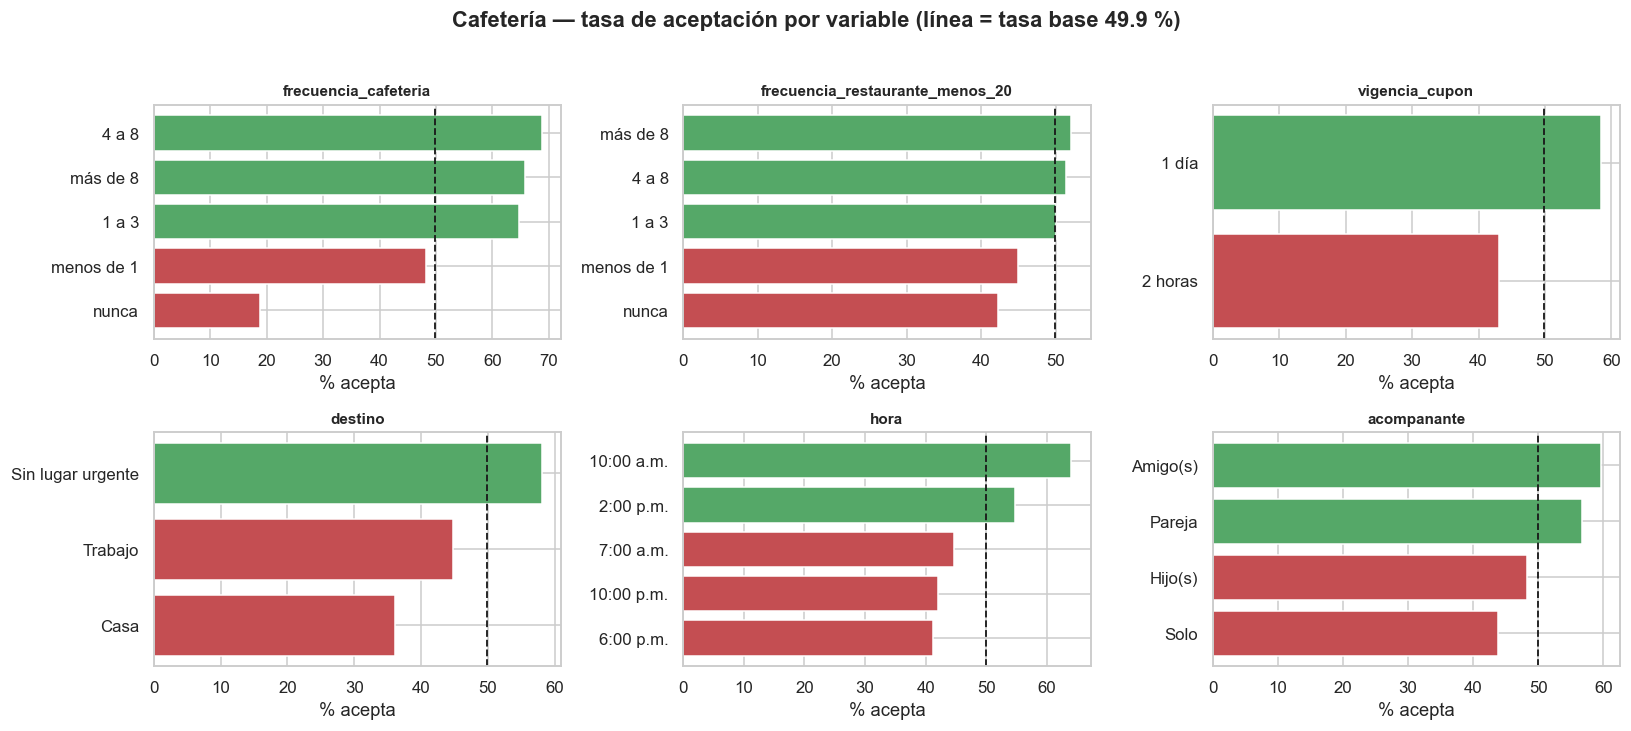

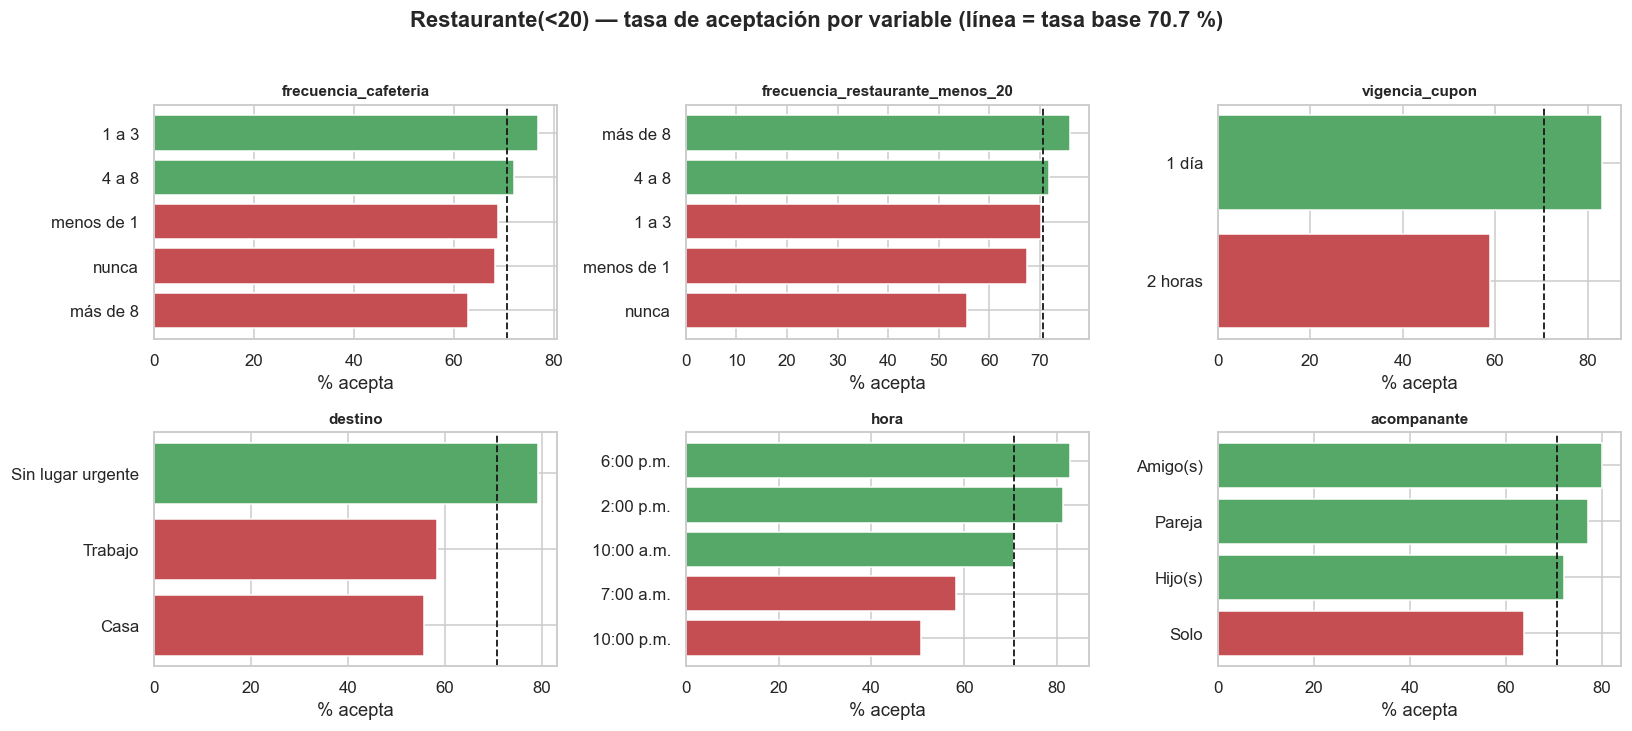

In [15]:
def tasa_aceptacion(df, col, cupon):
    sub = df[df.cupon == cupon]
    t = sub.groupby(col, observed=True).acepta_cupon.agg(
        n='size', tasa=lambda s: (s == 'Sí').mean()*100)
    return t[t.n >= 30].sort_values('tasa')

VARS_INTERES = ['frecuencia_cafeteria', 'frecuencia_restaurante_menos_20',
                'vigencia_cupon', 'destino', 'hora', 'acompanante']

for cup in CUPONES:
    base = (etiquetado_raw[etiquetado_raw.cupon == cup].acepta_cupon == 'Sí').mean()*100
    fig, axes = plt.subplots(2, 3, figsize=(15, 6.5))
    for ax, col in zip(axes.ravel(), VARS_INTERES):
        t = tasa_aceptacion(etiquetado_raw, col, cup)
        colores = ['#55a868' if v > base else '#c44e52' for v in t.tasa]
        ax.barh(t.index.astype(str), t.tasa, color=colores)
        ax.axvline(base, color='k', ls='--', lw=1.2)
        ax.set_title(col, fontsize=10); ax.set_xlabel('% acepta')
    fig.suptitle(f'{cup} — tasa de aceptación por variable (línea = tasa base {base:.1f} %)',
                 fontweight='bold', y=1.02)
    plt.show()

In [16]:
# Fuerza de asociación de cada variable con la etiqueta, por cupón (V de Cramér)
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    if ct.shape[0] < 2 or ct.shape[1] < 2:
        return np.nan
    chi2 = chi2_contingency(ct)[0]
    n = ct.values.sum()
    return np.sqrt((chi2/n) / (min(ct.shape) - 1))

candidatas = [c for c in etiquetado_raw.columns
              if c not in ('acepta_cupon', 'cupon', 'vehiculo', 'tiempo_cupon_mayor_5min')]
fuerza = pd.DataFrame({
    cup: {c: cramers_v(etiquetado_raw.loc[etiquetado_raw.cupon == cup, c],
                       etiquetado_raw.loc[etiquetado_raw.cupon == cup, 'acepta_cupon'])
          for c in candidatas}
    for cup in CUPONES})
fuerza['diferencia'] = (fuerza[CUPONES[0]] - fuerza[CUPONES[1]])
display(fuerza.sort_values(CUPONES[0], ascending=False).round(4))

,Cafetería,Restaurante(<20),diferencia
frecuencia_cafeteria,0.3779,0.0933,0.2846
destino,0.1853,0.2373,-0.0521
hora,0.1795,0.2831,-0.1037
ocupacion,0.1675,0.1411,0.0264
vigencia_cupon,0.1508,0.2661,-0.1153
acompanante,0.1460,0.1612,-0.0152
ingreso,0.1254,0.1116,0.0138
edad,0.1051,0.0851,0.0200
tiempo_cupon_mayor_15min,0.0933,0.1140,-0.0206
tiempo_cupon_mayor_25min,0.0884,0.2955,-0.2070


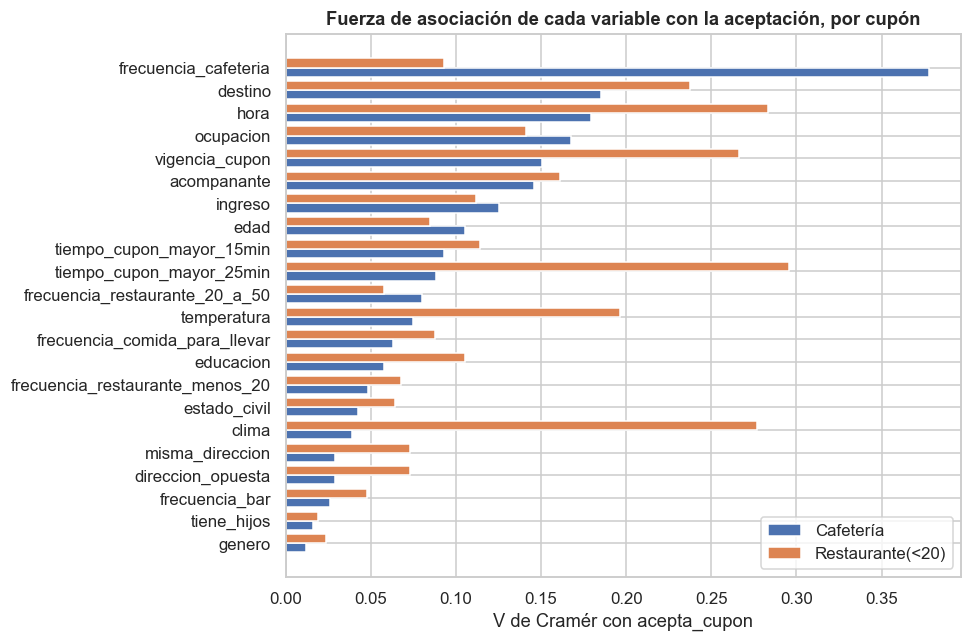

In [17]:
f = fuerza[CUPONES].sort_values(CUPONES[0])
fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(f))
ax.barh(y - 0.2, f[CUPONES[0]], height=0.4, label=CUPONES[0], color='#4c72b0')
ax.barh(y + 0.2, f[CUPONES[1]], height=0.4, label=CUPONES[1], color='#dd8452')
ax.set_yticks(y); ax.set_yticklabels(f.index)
ax.set_xlabel('V de Cramér con acepta_cupon'); ax.legend()
ax.set_title('Fuerza de asociación de cada variable con la aceptación, por cupón')
plt.show()

> **H9 — La señal está concentrada en Cafetería y repartida en Restaurante(<20).**
>
> En Cafetería, `frecuencia_cafeteria` destaca con una V de Cramér muy por encima del resto: quien
> visita cafeterías con frecuencia acepta el cupón de cafetería. Es una **coincidencia directa entre el
> hábito y la oferta**, y es el tipo de señal que un modelo aprende bien.
>
> En Restaurante(<20) **ninguna variable domina**: la distancia al establecimiento (0,2955), la hora
> (0,2831), el clima (0,2768), la vigencia del cupón (0,2661) y el destino (0,2373) quedan todas en
> una banda estrecha. La asociación total no es menor que en Cafetería, pero está **repartida**.
> Llamativamente, `frecuencia_restaurante_menos_20` —la que por simetría debería ser la más
> predictiva— tiene una asociación débil (0,0676). La interpretación es que, con una tasa base de aceptación del 70,7 %, *casi todo el
> mundo acepta*, y por tanto hay poco que discriminar: la variabilidad que queda se explica más por el
> contexto del trayecto (vigencia del cupón, hora, destino) que por el perfil del conductor.
>
> Nótese también que las dos variables de dirección tienen **exactamente la misma** V de Cramér
> (0,0293 y 0,0732), lo que confirma numéricamente la redundancia de H6.
>
> Esta asimetría es la que va a explicar, en la sección 10, por qué el F1 es más alto en
> Restaurante(<20) mientras que el ROC AUC es más alto en Cafetería.

### 2.6 Resumen de la exploración

| # | Hallazgo | Alcance | Decisión (sección 3) |
|:--|:---|:---|:---|
| H1 | `vehiculo` casi vacía | 99,15 % nula; 100 % en prueba | Eliminar |
| H2 | `tiempo_cupon_mayor_5min` constante | `Sí` en 12 664 filas | Eliminar |
| H3 | Ausencias en las 5 `frecuencia_*` | 0,84 % – 1,71 % | Imputar con la moda en el `Pipeline` |
| H4 | Duplicados exactos / contradictorios | 74 exactos; 23 combinaciones contradictorias | Eliminar los exactos; conservar las contradictorias como techo de desempeño |
| H5 | Desbalance muy distinto entre cupones | 49,9 % vs 70,7 % de `Sí` | Estratificar; evaluar balanceo solo en Restaurante(<20) |
| H6 | `direccion_opuesta` complemento exacto | correlación −1,0 | Eliminar una de las dos |
| H7 | Indicadores de distancia anidados | 3 binarias solapadas | Colapsar en una ordinal de 3 niveles |
| H8 | `temperatura` parcialmente redundante con `clima` | 2 de 3 climas la determinan | Conservar ambas y dejar que la importancia decida |
| H9 | Señal concentrada en Cafetería, difusa en Restaurante(<20) | — | Mismo tratamiento; se interpreta en la sección 10 |

Además: `cupon` se vuelve **constante** al filtrar por tipo, así que se elimina en cada subconjunto;
y `ocupacion` tiene **25 categorías** (mínimo 43 filas cada una), lo que al aplicar one-hot produce
muchas columnas dispersas — un punto relevante al interpretar su importancia en la sección 9.

<a name="s3"></a>
## 3. Limpieza y preparación de los datos

La preparación se separa en dos niveles, por una razón concreta de **fuga de información**:

| Nivel | Qué hace | Por qué ahí |
|:---|:---|:---|
| Funciones `preparar()` y `subconjunto()` | Eliminar columnas, colapsar los indicadores de distancia, filtrar por cupón, quitar duplicados | Son operaciones **deterministas por fila**: no estiman ningún parámetro a partir de los datos, así que aplicarlas antes de partir no filtra información |
| `Pipeline` de scikit-learn | Imputar, codificar y escalar | Estas **sí estiman parámetros** (moda, mediana, media, desviación, categorías). Deben ir dentro del `Pipeline` para que en cada pliegue de la validación cruzada se ajusten solo con los datos de entrenamiento de ese pliegue |

> Una consecuencia importante: `GridSearchCV` recibe el `Pipeline` completo, de modo que la imputación
> y el escalado se reajustan en cada uno de los 5 pliegues y en cada combinación de hiperparámetros.
> Imputar antes de la partición habría contaminado la evaluación.

In [18]:
# ============================================================
# Órdenes declarados en el diccionario de datos
# ============================================================
ORD_FRECUENCIA = ['nunca', 'menos de 1', '1 a 3', '4 a 8', 'más de 8']

ORDENES = {
    'hora'      : ['7:00 a.m.', '10:00 a.m.', '2:00 p.m.', '6:00 p.m.', '10:00 p.m.'],
    'edad'      : ['menor de 21', '21', '26', '31', '36', '41', '46', '50 o más'],
    'educacion' : ['Bachillerato incompleto', 'Bachillerato completo',
                   'Estudios universitarios sin título', 'Técnico/Tecnólogo',
                   'Pregrado', 'Posgrado (Maestría o Doctorado)'],
    'ingreso'   : ['Menos de $12.500', '$12.500 - $24.999', '$25.000 - $37.499',
                   '$37.500 - $49.999', '$50.000 - $62.499', '$62.500 - $74.999',
                   '$75.000 - $87.499', '$87.500 - $99.999', '$100.000 o más'],
    'frecuencia_bar'                  : ORD_FRECUENCIA,
    'frecuencia_cafeteria'            : ORD_FRECUENCIA,
    'frecuencia_comida_para_llevar'   : ORD_FRECUENCIA,
    'frecuencia_restaurante_menos_20' : ORD_FRECUENCIA,
    'frecuencia_restaurante_20_a_50'  : ORD_FRECUENCIA,
    'distancia_cupon'                 : ['hasta 15 min', '15 a 25 min', 'más de 25 min'],
}

ORDINALES = list(ORDENES.keys())
NUMERICAS = ['temperatura']
NOMINALES = ['destino', 'acompanante', 'clima', 'vigencia_cupon', 'genero',
             'estado_civil', 'tiene_hijos', 'ocupacion', 'misma_direccion']

DEMOGRAFICAS = {'genero', 'edad', 'estado_civil', 'tiene_hijos',
                'educacion', 'ocupacion', 'ingreso'}

print(f'{len(ORDINALES)} ordinales + {len(NUMERICAS)} numérica + {len(NOMINALES)} nominales '
      f'= {len(ORDINALES)+len(NUMERICAS)+len(NOMINALES)} variables predictoras')

10 ordinales + 1 numérica + 9 nominales = 20 variables predictoras


In [19]:
def preparar(df):
    '''Correcciones H1, H2, H6 y H7. Determinista por fila: no aprende nada del conjunto.'''
    d = df.copy()

    # H1: 99,15 % nula en entrenamiento y 100 % en prueba -> inutilizable
    d = d.drop(columns=['vehiculo'])

    # H7: los tres indicadores de distancia son una escala ordinal anidada.
    #     >5 min es constante (H2); >25 min implica >15 min.
    d['distancia_cupon'] = np.select(
        [d.tiempo_cupon_mayor_25min.eq('Sí'), d.tiempo_cupon_mayor_15min.eq('Sí')],
        ['más de 25 min', '15 a 25 min'], default='hasta 15 min')
    d = d.drop(columns=['tiempo_cupon_mayor_5min',      # H2: constante
                        'tiempo_cupon_mayor_15min',
                        'tiempo_cupon_mayor_25min'])

    # H6: complemento exacto de misma_direccion -> colinealidad perfecta
    d = d.drop(columns=['direccion_opuesta'])
    return d


def subconjunto(df, tipo_cupon, es_entrenamiento=True):
    '''Filtra por tipo de cupón. Solo elimina filas cuando es entrenamiento.'''
    s = df[df.cupon == tipo_cupon].copy()
    s = s.drop(columns=['cupon'])            # constante dentro del subconjunto
    if es_entrenamiento:
        antes = len(s)
        s = s.drop_duplicates()              # H4: solo las copias exactas
        s.attrs['duplicados_eliminados'] = antes - len(s)
    return s


etiquetado = preparar(etiquetado_raw)
prueba     = preparar(prueba_raw)

print(f'Columnas: {etiquetado_raw.shape[1]} -> {etiquetado.shape[1]} '
      f'(se eliminaron 5 y se creó distancia_cupon)')
print(f'\ndistancia_cupon:')
print(etiquetado.distancia_cupon.value_counts().reindex(ORDENES['distancia_cupon']).to_string())

Columnas: 26 -> 22 (se eliminaron 5 y se creó distancia_cupon)

distancia_cupon:
distancia_cupon
hasta 15 min     5551
15 a 25 min      5602
más de 25 min    1511


In [20]:
# ---- Construcción de los subconjuntos por cupón ----
DATOS = {}
traza = []
for cup in CUPONES:
    s  = subconjunto(etiquetado, cup, es_entrenamiento=True)
    st = subconjunto(prueba,     cup, es_entrenamiento=False)

    X = s.drop(columns=['acepta_cupon'])
    y = (s.acepta_cupon == 'Sí').astype(int)          # 1 = Sí (acepta), 0 = No

    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

    DATOS[cup] = dict(X=X, y=y, X_tr=X_tr, X_te=X_te, y_tr=y_tr, y_te=y_te, prueba=st)
    traza.append({
        'Cupón': cup,
        'filas originales': len(etiquetado[etiquetado.cupon == cup]),
        'duplicados eliminados': s.attrs['duplicados_eliminados'],
        'filas finales': len(s),
        'entrenamiento': len(X_tr), 'prueba (25 %)': len(X_te),
        '% Sí entrenamiento': round(y_tr.mean()*100, 2),
        '% Sí prueba': round(y_te.mean()*100, 2),
        'clase minoritaria': 'Sí' if y.mean() < .5 else 'No',
        'filas sin etiqueta': len(st),
    })

display(pd.DataFrame(traza).set_index('Cupón').T)
print('La estratificación mantiene la proporción de clases prácticamente idéntica entre '
      'entrenamiento y prueba.')

Cupón,Cafetería,Restaurante(<20)
filas originales,3986,2776
duplicados eliminados,7,7
filas finales,3979,2769
entrenamiento,2984,2076
prueba (25 %),995,693
% Sí entrenamiento,49.83,70.76
% Sí prueba,49.85,70.71
clase minoritaria,Sí,No
filas sin etiqueta,10,10


La estratificación mantiene la proporción de clases prácticamente idéntica entre entrenamiento y prueba.


In [21]:
# ---- Verificación: los órdenes declarados cubren todos los valores observados ----
print('Validación de las categorías declaradas frente a las observadas:')
problemas = 0
for col, orden in ORDENES.items():
    obs = set(etiquetado[col].dropna().unique()) | set(prueba[col].dropna().unique())
    falta = obs - set(orden)
    if falta:
        print(f'  {col}: valores NO declarados -> {falta}'); problemas += 1
for col in NOMINALES:
    nuevas = set(prueba[col].dropna().unique()) - set(etiquetado[col].dropna().unique())
    if nuevas:
        print(f'  {col}: categorías en prueba no vistas en entrenamiento -> {nuevas}'); problemas += 1
print(f'  -> {"Sin problemas: todas las categorías están declaradas y cubiertas." if not problemas else f"{problemas} problemas"}')

Validación de las categorías declaradas frente a las observadas:
  -> Sin problemas: todas las categorías están declaradas y cubiertas.


In [22]:
def construir_preproceso(X_ref, escalar=False):
    '''
    Preprocesamiento. Las categorías de los nominales se fijan desde X_ref (el conjunto de
    entrenamiento) para que el ancho de la matriz de salida sea constante entre pliegues de la
    validación cruzada: si un pliegue no contiene alguna de las 25 ocupaciones, el one-hot
    produciría menos columnas y SMOTENC recibiría índices desalineados.
    '''
    cat_ordinales = [ORDENES[c] for c in ORDINALES]
    cat_nominales = [sorted(X_ref[c].dropna().unique().tolist()) for c in NOMINALES]

    pasos_ord = [('codificar', OrdinalEncoder(categories=cat_ordinales,
                                              handle_unknown='use_encoded_value',
                                              unknown_value=np.nan,
                                              encoded_missing_value=np.nan)),
                 ('imputar', SimpleImputer(strategy='most_frequent'))]   # H3
    pasos_num = [('imputar', SimpleImputer(strategy='median'))]

    if escalar:        # solo la regresión logística lo necesita
        pasos_ord.append(('escalar', StandardScaler()))
        pasos_num.append(('escalar', StandardScaler()))

    return ColumnTransformer([
        ('ord', Pipeline(pasos_ord), ORDINALES),
        ('num', Pipeline(pasos_num), NUMERICAS),
        ('nom', Pipeline([('imputar', SimpleImputer(strategy='most_frequent')),
                          ('codificar', OneHotEncoder(categories=cat_nominales,
                                                      handle_unknown='ignore',
                                                      drop='first'))]), NOMINALES),
    ])


# Comprobación del ancho de la matriz resultante
for cup in CUPONES:
    pre = construir_preproceso(DATOS[cup]['X_tr'])
    M = pre.fit_transform(DATOS[cup]['X_tr'])
    n_oh = M.shape[1] - len(ORDINALES) - len(NUMERICAS)
    DATOS[cup]['n_ord_num'] = len(ORDINALES) + len(NUMERICAS)
    DATOS[cup]['ancho'] = M.shape[1]
    print(f'{cup:20s} matriz {M.shape[0]} x {M.shape[1]}  '
          f'({len(ORDINALES)} ordinales + {len(NUMERICAS)} numérica + {n_oh} binarias one-hot)')

Cafetería            matriz 2984 x 50  (10 ordinales + 1 numérica + 39 binarias one-hot)
Restaurante(<20)     matriz 2076 x 50  (10 ordinales + 1 numérica + 39 binarias one-hot)


#### Justificación de las decisiones de preparación

| Decisión | Alternativa descartada | Por qué |
|:---|:---|:---|
| Eliminar `vehiculo` | Imputar la moda | 99,15 % nula y **100 % nula en prueba**: no habría nada que imputar donde importa |
| Eliminar `tiempo_cupon_mayor_5min` | Conservarla | Constante: varianza cero, aporte nulo por construcción |
| Colapsar los 3 indicadores de distancia en una ordinal | Dejar las 3 binarias | Están anidadas; una ordinal con el mismo contenido es más interpretable y evita columnas solapadas |
| Eliminar `direccion_opuesta` | Conservar ambas | Correlación −1,0: colinealidad perfecta que vuelve arbitrarios los coeficientes de la logística |
| `OrdinalEncoder` con el orden del diccionario | One-hot para las 9 ordinales | Preserva el orden (*nunca* < *menos de 1* < …), permite al árbol partir con un solo umbral y reduce la dimensionalidad |
| One-hot con `drop='first'` para las nominales | `OrdinalEncoder` | Imponer un orden arbitrario a `ocupacion` o `estado_civil` sería incorrecto; `drop='first'` evita la colinealidad de la variable *dummy* redundante |
| Imputar la moda en las frecuencias | Eliminar las filas | Son 0,84 %–1,71 %: eliminar descarta información útil de las demás columnas de esas filas |
| Escalar **solo** para la logística | Escalar siempre | Los árboles y Random Forest son invariantes a transformaciones monótonas; escalar no cambia nada y dificulta la lectura de los umbrales |
| Fijar las categorías nominales desde `X_tr` | `handle_unknown='ignore'` sin `categories` | Garantiza ancho constante entre pliegues, requisito para alinear los índices categóricos de SMOTENC |
| Conservar las 23 contradicciones | Eliminarlas | Son parte real del fenómeno; eliminarlas inflaría artificialmente el desempeño |
| Dos modelos independientes por algoritmo | Un modelo conjunto con `cupon` como variable | El enunciado pide un modelo por tipo de cupón, y la sección 2.5 muestra que los predictores relevantes son distintos en cada uno |

<a name="s4"></a>
## 4. Modelos de regresión logística

Infraestructura común a las secciones 4, 5 y 6: una función que construye el `Pipeline`, ejecuta
`GridSearchCV` con `StratifiedKFold(5)` optimizando F1, y evalúa sobre la partición de prueba.

**Las métricas que reportamos y por qué:**

* `Recall (Sí)`, `Precision (Sí)`, `F1 (Sí)` — las tres que pide la actividad 7, sobre la clase
  positiva (acepta).
* `Recall (No)` — el recall de la **clase minoritaria en Restaurante(<20)**, necesario para la
  actividad 6 y para no dejarse engañar por el F1 de la clase mayoritaria.
* `F1 macro` — promedio no ponderado de los F1 de ambas clases; penaliza a los modelos que solo
  aciertan la clase frecuente.
* `ROC AUC` — capacidad de ordenamiento, independiente del umbral y **del desbalance**. Es la métrica
  que permite comparar de forma justa entre los dos cupones, que tienen tasas base distintas.

In [23]:
RESULTADOS = []      # una fila por (cupón, modelo)
MODELOS    = {}      # (cupón, modelo) -> GridSearchCV ajustado

def calcular_metricas(y, pred, prob):
    return {
        'Recall (Sí)'    : recall_score(y, pred, pos_label=1),
        'Precision (Sí)' : precision_score(y, pred, pos_label=1),
        'F1 (Sí)'        : f1_score(y, pred, pos_label=1),
        'Recall (No)'    : recall_score(y, pred, pos_label=0),
        'F1 macro'       : f1_score(y, pred, average='macro'),
        'Exactitud'      : accuracy_score(y, pred),
        'ROC AUC'        : roc_auc_score(y, prob),
    }


def ajustar(cupon, nombre, estimador, grid, escalar=False):
    '''Pipeline + GridSearchCV(5 pliegues, F1) + evaluación sobre la partición de prueba.'''
    d = DATOS[cupon]
    t0 = time.time()

    pipe = Pipeline([('preproceso', construir_preproceso(d['X_tr'], escalar=escalar)),
                     ('modelo', estimador)])
    # n_jobs=N_JOBS (=1): la rejilla se recorre en serie y el paralelismo queda en el
    # Random Forest. Anidar ambos niveles provoca TerminatedWorkerError por memoria.
    gs = GridSearchCV(pipe, grid, scoring=SCORING, cv=CV, n_jobs=N_JOBS, refit=True)
    gs.fit(d['X_tr'], d['y_tr'])

    pred = gs.predict(d['X_te'])
    prob = gs.predict_proba(d['X_te'])[:, 1]

    fila = {'Cupón': cupon, 'Modelo': nombre}
    fila.update(calcular_metricas(d['y_te'], pred, prob))
    fila['F1 CV'] = gs.best_score_
    fila['combinaciones'] = len(gs.cv_results_['params'])
    RESULTADOS.append(fila); MODELOS[(cupon, nombre)] = gs

    print(f'  {cupon:18s} | F1 CV={gs.best_score_:.4f}  F1(Sí)={fila["F1 (Sí)"]:.4f}  '
          f'Recall(Sí)={fila["Recall (Sí)"]:.4f}  Precision(Sí)={fila["Precision (Sí)"]:.4f}  '
          f'Recall(No)={fila["Recall (No)"]:.4f}  AUC={fila["ROC AUC"]:.4f}')
    print(f'                     | mejores hiperparámetros: '
          f'{ {k.replace("modelo__",""): v for k, v in gs.best_params_.items()} }  '
          f'({len(gs.cv_results_["params"])} combinaciones, {time.time()-t0:.0f} s)')
    return gs

print('Infraestructura de ajuste y evaluación definida.')

Infraestructura de ajuste y evaluación definida.


**Rejilla de la regresión logística.** El enunciado pide explorar *al menos el tipo de regularización
y el solver*. La rejilla se divide en dos bloques porque **no todos los solvers admiten todas las
penalizaciones**: `lbfgs` solo soporta L2, mientras que `liblinear` y `saga` admiten L1 y L2.
Definirla como una lista de diccionarios evita que `GridSearchCV` intente combinaciones inválidas.
Añadimos `C` (inverso de la fuerza de regularización) porque sin él la comparación entre L1 y L2
sería incompleta.

In [24]:
GRID_LOGISTICA = [
    {'modelo__penalty': ['l2'], 'modelo__solver': ['lbfgs', 'liblinear', 'saga'],
     'modelo__C': [0.01, 0.1, 1, 10]},
    {'modelo__penalty': ['l1'], 'modelo__solver': ['liblinear', 'saga'],
     'modelo__C': [0.01, 0.1, 1, 10]},
]

print('ACTIVIDAD 3 — Regresión logística (una por tipo de cupón)\n')
for cup in CUPONES:
    ajustar(cup, 'Regresión logística',
            LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
            GRID_LOGISTICA, escalar=True)

ACTIVIDAD 3 — Regresión logística (una por tipo de cupón)



  Cafetería          | F1 CV=0.7076  F1(Sí)=0.6881  Recall(Sí)=0.6915  Precision(Sí)=0.6846  Recall(No)=0.6834  AUC=0.7387
                     | mejores hiperparámetros: {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}  (20 combinaciones, 11 s)


  Restaurante(<20)   | F1 CV=0.8450  F1(Sí)=0.8483  Recall(Sí)=0.9531  Precision(Sí)=0.7643  Recall(No)=0.2906  AUC=0.6747
                     | mejores hiperparámetros: {'C': 0.01, 'penalty': 'l1', 'solver': 'liblinear'}  (20 combinaciones, 8 s)


<a name="s5"></a>
## 5. Modelos de árbol de decisión

El enunciado pide explorar **profundidad máxima, mínimo de muestras por hoja y criterio de división**.
Incluimos `max_depth=None` en la rejilla de forma deliberada: permite que la validación cruzada
decida si conviene un árbol sin restricción, y el resultado es informativo sobre el sobreajuste.

In [25]:
GRID_ARBOL = {
    'modelo__max_depth'        : [3, 5, 8, 12, None],
    'modelo__min_samples_leaf' : [1, 5, 20, 50],
    'modelo__criterion'        : ['gini', 'entropy'],
}

print('ACTIVIDAD 4 — Árbol de decisión (uno por tipo de cupón)\n')
for cup in CUPONES:
    ajustar(cup, 'Árbol de decisión',
            DecisionTreeClassifier(random_state=RANDOM_STATE), GRID_ARBOL)

ACTIVIDAD 4 — Árbol de decisión (uno por tipo de cupón)



  Cafetería          | F1 CV=0.7149  F1(Sí)=0.7073  Recall(Sí)=0.8065  Precision(Sí)=0.6299  Recall(No)=0.5291  AUC=0.7156
                     | mejores hiperparámetros: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1}  (40 combinaciones, 11 s)


  Restaurante(<20)   | F1 CV=0.8363  F1(Sí)=0.8333  Recall(Sí)=0.9184  Precision(Sí)=0.7627  Recall(No)=0.3103  AUC=0.7297
                     | mejores hiperparámetros: {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 50}  (40 combinaciones, 9 s)


> La validación cruzada elige árboles **poco profundos** en los dos cupones (profundidad 3 en Cafetería
> y 5 en Restaurante(<20), este último con un mínimo de 50 muestras por hoja). Es un resultado
> esperable y sano: con 25 categorías de ocupación y más de 40 columnas tras la codificación, un árbol
> sin poda memoriza el ruido —incluidas las 23 contradicciones del hallazgo H4— y generaliza peor. La
> contrapartida es que un árbol tan simple tiene **poca capacidad**, lo que se ve en el recall de la
> clase minoritaria.

<a name="s6"></a>
## 6. Modelos de Random Forest

El enunciado pide explorar **número de árboles, profundidad máxima y mínimo de muestras por hoja**.
A diferencia del árbol individual, aquí `max_depth=None` suele ser una buena elección: el *bagging*
y la selección aleatoria de variables en cada división controlan la varianza que un único árbol
profundo no controlaría.

In [26]:
GRID_RF = {
    'modelo__n_estimators'     : [200, 500],
    'modelo__max_depth'        : [8, 15, None],
    'modelo__min_samples_leaf' : [1, 5, 20],
}

print('ACTIVIDAD 5 — Random Forest (uno por tipo de cupón)\n')
for cup in CUPONES:
    ajustar(cup, 'Random Forest',
            RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), GRID_RF)

ACTIVIDAD 5 — Random Forest (uno por tipo de cupón)



  Cafetería          | F1 CV=0.7558  F1(Sí)=0.7876  Recall(Sí)=0.7964  Precision(Sí)=0.7791  Recall(No)=0.7756  AUC=0.8573
                     | mejores hiperparámetros: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 500}  (18 combinaciones, 58 s)


  Restaurante(<20)   | F1 CV=0.8518  F1(Sí)=0.8531  Recall(Sí)=0.9122  Precision(Sí)=0.8011  Recall(No)=0.4532  AUC=0.8004
                     | mejores hiperparámetros: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 500}  (18 combinaciones, 45 s)


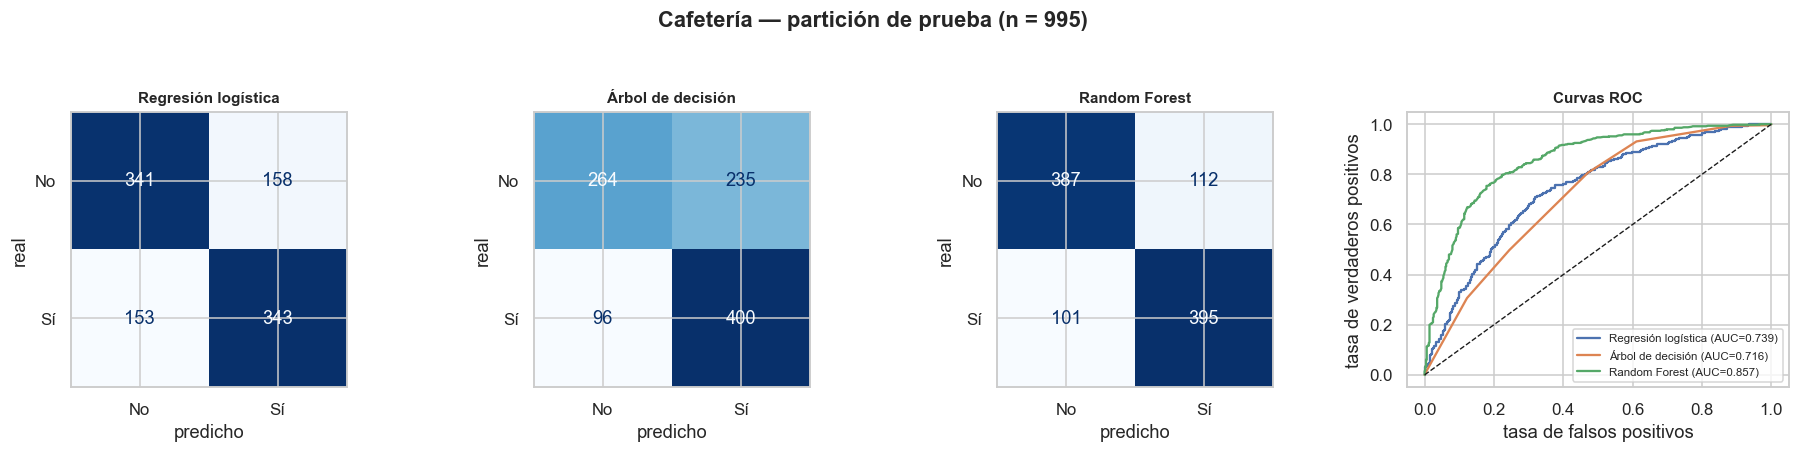

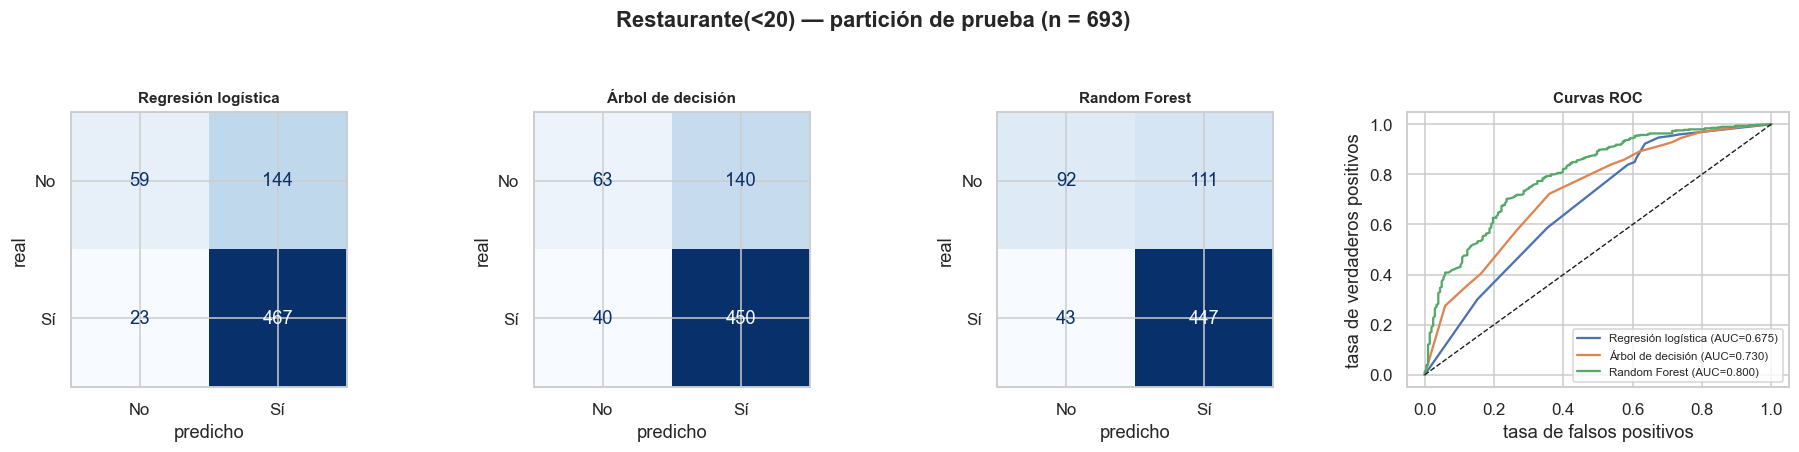

In [27]:
# ---- Matrices de confusión y curvas ROC de los tres algoritmos ----
ALGORITMOS = ['Regresión logística', 'Árbol de decisión', 'Random Forest']

for cup in CUPONES:
    d = DATOS[cup]
    fig, axes = plt.subplots(1, 4, figsize=(17, 3.9))
    for ax, alg in zip(axes[:3], ALGORITMOS):
        gs = MODELOS[(cup, alg)]
        cm = confusion_matrix(d['y_te'], gs.predict(d['X_te']))
        ConfusionMatrixDisplay(cm, display_labels=['No', 'Sí']).plot(
            ax=ax, cmap='Blues', colorbar=False, values_format='d')
        ax.set_title(f'{alg}', fontsize=10)
        ax.set_xlabel('predicho'); ax.set_ylabel('real')

    for alg, color in zip(ALGORITMOS, ['#4c72b0', '#dd8452', '#55a868']):
        gs = MODELOS[(cup, alg)]
        prob = gs.predict_proba(d['X_te'])[:, 1]
        fpr, tpr, _ = roc_curve(d['y_te'], prob)
        axes[3].plot(fpr, tpr, color=color,
                     label=f'{alg} (AUC={roc_auc_score(d["y_te"], prob):.3f})')
    axes[3].plot([0, 1], [0, 1], 'k--', lw=.9)
    axes[3].set_xlabel('tasa de falsos positivos'); axes[3].set_ylabel('tasa de verdaderos positivos')
    axes[3].set_title('Curvas ROC', fontsize=10); axes[3].legend(fontsize=7.5, loc='lower right')

    fig.suptitle(f'{cup} — partición de prueba (n = {len(d["y_te"])})', fontweight='bold', y=1.05)
    plt.show()

<a name="s7"></a>
## 7. Evaluación del balanceo de clases en Restaurante(<20)

Punto de partida: en Restaurante(<20) la proporción es **70,7 % `Sí` / 29,3 % `No`**, de modo que
**la clase minoritaria es `No`**. Un clasificador que respondiera siempre `Sí` lograría un F1 de 0,83
sobre la clase positiva con un recall de `No` igual a **cero**. Ese es el riesgo concreto que la
actividad 6 pide examinar.

### Por qué SMOTE**NC** y no SMOTE

SMOTE genera ejemplos sintéticos **interpolando linealmente** entre vecinos de la clase minoritaria.
Esa operación presupone variables continuas. Aquí **todas las variables son categóricas**, y tras el
one-hot la interpolación produciría valores como `ocupacion_Estudiante = 0,37`, que no corresponde a
ningún conductor posible.

`SMOTENC` (*SMOTE for Nominal and Continuous*) es la variante diseñada para datos mixtos: interpola
las columnas continuas y, en las categóricas, asigna **la categoría más frecuente entre los vecinos**.
Le declaramos qué columnas de la matriz preprocesada son categóricas: las binarias del one-hot. Las
ordinales se tratan como continuas, lo que es defendible porque son escalas ordenadas.

Comparamos cuatro estrategias, e incluimos `class_weight='balanced'` como alternativa que **no genera
datos sintéticos** sino que repondera el error, para tener un punto de comparación honesto.

In [28]:
d = DATOS['Restaurante(<20)']

# Índices de las columnas categóricas (one-hot) dentro de la matriz preprocesada
IDX_CATEGORICAS = list(range(d['n_ord_num'], d['ancho']))
print(f"Matriz preprocesada: {d['ancho']} columnas")
print(f"  columnas 0-{d['n_ord_num']-1}  : ordinales y numérica (tratadas como continuas)")
print(f"  columnas {d['n_ord_num']}-{d['ancho']-1} : binarias one-hot -> declaradas categóricas en SMOTENC")
print(f"\nDistribución en entrenamiento: "
      f"Sí={int(d['y_tr'].sum())}, No={int((d['y_tr']==0).sum())} "
      f"({(1-d['y_tr'].mean())*100:.2f} % minoritaria)")

# Hiperparámetros del mejor Random Forest, para aislar el efecto del balanceo
MEJORES_RF = {k.replace('modelo__', ''): v
              for k, v in MODELOS[('Restaurante(<20)', 'Random Forest')].best_params_.items()}
print(f'\nSe fijan los hiperparámetros del mejor RF de la sección 6 para que la única diferencia '
      f'entre las cuatro estrategias sea el balanceo:\n  {MEJORES_RF}')

Matriz preprocesada: 50 columnas
  columnas 0-10  : ordinales y numérica (tratadas como continuas)
  columnas 11-49 : binarias one-hot -> declaradas categóricas en SMOTENC

Distribución en entrenamiento: Sí=1469, No=607 (29.24 % minoritaria)

Se fijan los hiperparámetros del mejor RF de la sección 6 para que la única diferencia entre las cuatro estrategias sea el balanceo:
  {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 500}


In [29]:
def evaluar_balanceo(nombre, pipe):
    '''Evalúa una estrategia de balanceo con validación cruzada y sobre la partición de prueba.'''
    cv = cross_validate(pipe, d['X_tr'], d['y_tr'], cv=CV, n_jobs=N_JOBS,
                        scoring={'f1': 'f1', 'f1_macro': 'f1_macro', 'auc': 'roc_auc'})
    pipe.fit(d['X_tr'], d['y_tr'])
    pred = pipe.predict(d['X_te']); prob = pipe.predict_proba(d['X_te'])[:, 1]
    r = {'Estrategia': nombre,
         'F1 (Sí)'                 : f1_score(d['y_te'], pred),
         'Recall (Sí)'             : recall_score(d['y_te'], pred),
         'Precision (Sí)'          : precision_score(d['y_te'], pred),
         'Recall (No) MINORITARIA' : recall_score(d['y_te'], pred, pos_label=0),
         'Precision (No)'          : precision_score(d['y_te'], pred, pos_label=0),
         'F1 (No)'                 : f1_score(d['y_te'], pred, pos_label=0),
         'F1 macro'                : f1_score(d['y_te'], pred, average='macro'),
         'Exactitud'               : accuracy_score(d['y_te'], pred),
         'ROC AUC'                 : roc_auc_score(d['y_te'], prob),
         'F1 CV'                   : cv['test_f1'].mean(),
         'F1 macro CV'             : cv['test_f1_macro'].mean()}
    print(f'  {nombre:26s} F1(Sí)={r["F1 (Sí)"]:.4f}  '
          f'Recall(No)={r["Recall (No) MINORITARIA"]:.4f}  '
          f'F1 macro={r["F1 macro"]:.4f}  AUC={r["ROC AUC"]:.4f}')
    return r


def rf(**extra):
    return RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **MEJORES_RF, **extra)

def pre():
    return construir_preproceso(d['X_tr'])

print('ACTIVIDAD 6 — Comparación de estrategias de balanceo en Restaurante(<20)\n')
balanceo = [
    evaluar_balanceo('Sin balanceo',
        Pipeline([('preproceso', pre()), ('modelo', rf())])),
    evaluar_balanceo('SMOTENC (total, 1:1)',
        ImbPipeline([('preproceso', pre()),
                     ('balanceo', SMOTENC(categorical_features=IDX_CATEGORICAS,
                                          random_state=RANDOM_STATE)),
                     ('modelo', rf())])),
    evaluar_balanceo('SMOTENC (parcial, 0.6)',
        ImbPipeline([('preproceso', pre()),
                     ('balanceo', SMOTENC(categorical_features=IDX_CATEGORICAS,
                                          sampling_strategy=0.6,
                                          random_state=RANDOM_STATE)),
                     ('modelo', rf())])),
    evaluar_balanceo('class_weight=balanced',
        Pipeline([('preproceso', pre()), ('modelo', rf(class_weight='balanced'))])),
]

tabla_balanceo = pd.DataFrame(balanceo).set_index('Estrategia')
display(tabla_balanceo.round(4))

ACTIVIDAD 6 — Comparación de estrategias de balanceo en Restaurante(<20)



  Sin balanceo               F1(Sí)=0.8531  Recall(No)=0.4532  F1 macro=0.6987  AUC=0.8004


  SMOTENC (total, 1:1)       F1(Sí)=0.8414  Recall(No)=0.5172  F1 macro=0.7037  AUC=0.8020


  SMOTENC (parcial, 0.6)     F1(Sí)=0.8544  Recall(No)=0.4877  F1 macro=0.7109  AUC=0.7978


  class_weight=balanced      F1(Sí)=0.8585  Recall(No)=0.4532  F1 macro=0.7055  AUC=0.7988


,F1 (Sí),Recall (Sí),Precision (Sí),Recall (No) MINORITARIA,Precision (No),F1 (No),F1 macro,Exactitud,ROC AUC,F1 CV,F1 macro CV
Estrategia,,,,,,,,,,,
Sin balanceo,0.8531,0.9122,0.8011,0.4532,0.6815,0.5444,0.6987,0.7778,0.8004,0.8518,0.6918
"SMOTENC (total, 1:1)",0.8414,0.8714,0.8133,0.5172,0.6250,0.5660,0.7037,0.7677,0.8020,0.8420,0.6981
"SMOTENC (parcial, 0.6)",0.8544,0.9041,0.8099,0.4877,0.6781,0.5673,0.7109,0.7821,0.7978,0.8492,0.7010
class_weight=balanced,0.8585,0.9224,0.8028,0.4532,0.7077,0.5526,0.7055,0.7850,0.7988,0.8497,0.6804


In [30]:
# Conteos absolutos: el recall de la minoritaria traducido a número de conductores.
n_no = int((d['y_te'] == 0).sum())
print(f'La partición de prueba de Restaurante(<20) tiene {len(d["y_te"])} filas, '
      f'de las cuales {n_no} son rechazos (clase minoritaria "No").\n')
detectados = pd.DataFrame({
    'recall (No)': tabla_balanceo['Recall (No) MINORITARIA'],
    'rechazos detectados': (tabla_balanceo['Recall (No) MINORITARIA']*n_no).round(0).astype(int),
    f'de un total de': n_no})
detectados['frente a sin balanceo'] = (detectados['rechazos detectados'] -
                                       detectados.loc['Sin balanceo', 'rechazos detectados'])
display(detectados)

base = tabla_balanceo.loc['Sin balanceo']
delta = (tabla_balanceo - base).drop(index='Sin balanceo')
print('Cambio respecto a NO balancear (positivo = mejora):\n')
display(delta[['F1 (Sí)', 'Recall (No) MINORITARIA', 'F1 (No)', 'F1 macro', 'ROC AUC']]
        .round(4).style.format('{:+.4f}')
        .background_gradient(cmap='RdYlGn', vmin=-0.08, vmax=0.08))

La partición de prueba de Restaurante(<20) tiene 693 filas, de las cuales 203 son rechazos (clase minoritaria "No").



,recall (No),rechazos detectados,de un total de,frente a sin balanceo
Estrategia,,,,
Sin balanceo,0.453202,92,203,0
"SMOTENC (total, 1:1)",0.517241,105,203,13
"SMOTENC (parcial, 0.6)",0.487685,99,203,7
class_weight=balanced,0.453202,92,203,0


Cambio respecto a NO balancear (positivo = mejora):



,F1 (Sí),Recall (No) MINORITARIA,F1 (No),F1 macro,ROC AUC
Estrategia,,,,,
"SMOTENC (total, 1:1)",-0.0117,+0.0640,+0.0217,+0.0050,+0.0016
"SMOTENC (parcial, 0.6)",+0.0013,+0.0345,+0.0230,+0.0121,-0.0026
class_weight=balanced,+0.0054,+0.0000,+0.0082,+0.0068,-0.0016


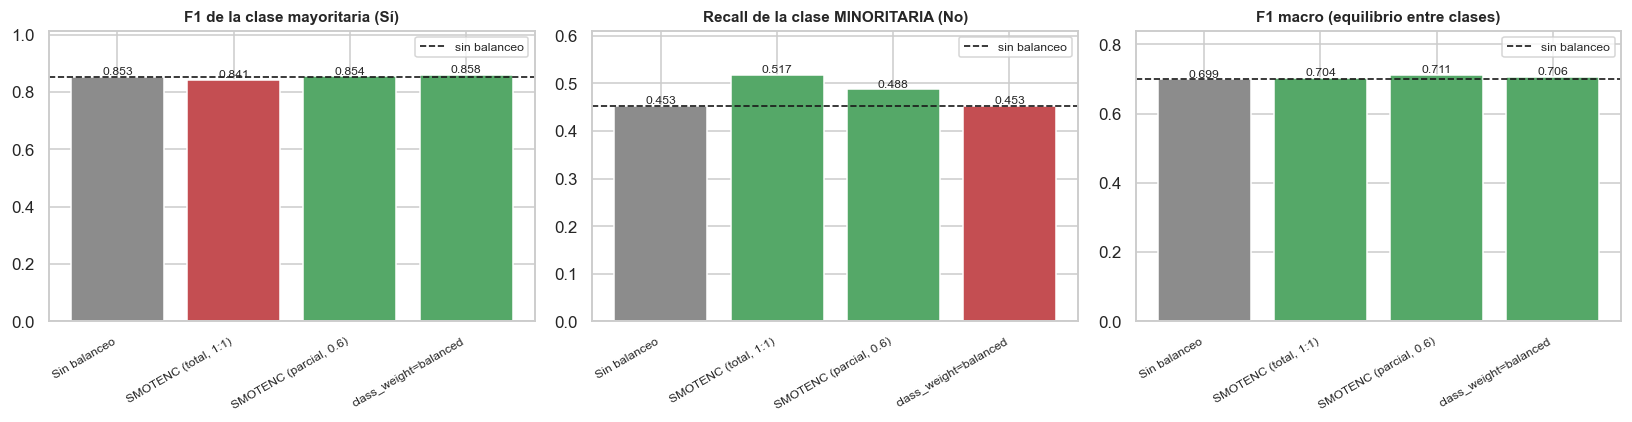

In [31]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
e = tabla_balanceo.index

for a, (col, titulo) in zip(ax, [('F1 (Sí)', 'F1 de la clase mayoritaria (Sí)'),
                                 ('Recall (No) MINORITARIA', 'Recall de la clase MINORITARIA (No)'),
                                 ('F1 macro', 'F1 macro (equilibrio entre clases)')]):
    v = tabla_balanceo[col]
    colores = ['#8c8c8c'] + ['#55a868' if x > v.iloc[0] else '#c44e52' for x in v.iloc[1:]]
    a.bar(range(len(v)), v, color=colores)
    a.axhline(v.iloc[0], color='k', ls='--', lw=1.1, label='sin balanceo')
    a.set_xticks(range(len(v))); a.set_xticklabels(e, rotation=30, ha='right', fontsize=8)
    a.set_title(titulo, fontsize=10); a.set_ylim(0, max(v)*1.18); a.legend(fontsize=8)
    for i, x in enumerate(v):
        a.text(i, x, f'{x:.3f}', ha='center', va='bottom', fontsize=8)
plt.show()

### Recomendación sobre el balanceo

**Los números.** Partiendo del Random Forest sin balancear (F1 Sí = 0,8531; recall No = 0,4532;
F1 macro = 0,6987):

| Estrategia | F1 (Sí) | Recall (No) | F1 macro | Lectura |
|:---|---:|---:|---:|:---|
| Sin balanceo | 0,8531 | 0,4532 | 0,6987 | Referencia |
| SMOTENC total (1:1) | 0,8414 | **0,5172** | 0,7037 | Gana 6,4 puntos de recall en la minoritaria a cambio de 1,2 de F1 |
| **SMOTENC parcial (0,6)** | 0,8544 | 0,4877 | **0,7109** | Mejora las tres métricas a la vez |
| `class_weight='balanced'` | 0,8585 | 0,4532 | 0,7055 | Sube el F1 pero **no mueve el recall de la minoritaria** |

**Conclusión: sí conviene aplicar balanceo, pero parcial, no total.**

El razonamiento, y los tres matices que importan:

1. **SMOTENC total (1:1) mejora claramente lo que se busca mejorar.** El recall de la clase
   minoritaria pasa de 0,4532 a **0,5172**, una ganancia relativa del 14 %: el modelo detecta la mitad
   de los rechazos en lugar de menos de la mitad. El costo es 1,2 puntos de F1 en la clase mayoritaria,
   porque al reponderar la frontera algunos `Sí` se clasifican como `No`. Es exactamente el
   intercambio que uno espera del balanceo, y el F1 macro confirma que el cambio neto es favorable.

2. **SMOTENC parcial (`sampling_strategy=0.6`) es la mejor opción global**, y es la que recomendamos.
   En lugar de igualar las clases, lleva la minoritaria al 60 % de la mayoritaria. Consigue el
   **mejor F1 macro (0,7109)** y, a diferencia del balanceo total, **no sacrifica F1 en la clase
   positiva** (0,8544 frente a 0,8531). Esto tiene una explicación: el desbalance 71/29 es moderado,
   no extremo, así que forzar la paridad total sobrecorrige e introduce más ejemplos sintéticos de los
   necesarios.

3. **`class_weight='balanced'` no sirve para este objetivo, y es un hallazgo útil.** Mejora el F1 de
   la clase positiva (0,8585, el más alto de los cuatro) pero deja el recall de la minoritaria
   **exactamente igual** (0,4532). Es decir: parece mejor si uno solo mira el F1, pero no resuelve el
   problema que motivó la actividad. Es un buen recordatorio de que **la métrica elegida determina la
   conclusión**, y de por qué el enunciado pide mirar las dos.

**La decisión depende del objetivo de negocio, y conviene decirlo explícitamente a Ruta Alpes.** Si
el objetivo es maximizar cupones aceptados, el balanceo aporta poco: sin balancear ya se detecta el
91 % de los `Sí`. Pero el enunciado señala que enviar ofertas irrelevantes **genera molestia**, y
evitar esa molestia significa identificar correctamente los `No`. Bajo ese objetivo, el balanceo es
necesario, y el ROC AUC —que es insensible al umbral— se mantiene prácticamente constante
(0,7978–0,8020), lo que confirma que el balanceo **no mejora la capacidad de ordenamiento del modelo**
sino que **reubica el umbral de decisión** hacia un punto operativo más equilibrado.

> **Alternativa sin datos sintéticos.** Conseguir ese mismo efecto ajustando el umbral de decisión
> sobre las probabilidades del modelo sin balancear —en lugar de generar ejemplos artificiales— es una
> opción más simple y controlable en producción. Lo señalamos como recomendación en la sección 10.

<a name="s8"></a>
## 8. Tabla comparativa y selección del mejor modelo

Métricas sobre la **partición de prueba del 25 %**, que ningún modelo vio durante el ajuste de
hiperparámetros. Se incluye el F1 de validación cruzada sobre el entrenamiento para verificar que el
orden entre algoritmos no depende del azar de una sola partición.

In [32]:
comparativa = pd.DataFrame(RESULTADOS).set_index(['Cupón', 'Modelo'])
COLS_RUBRICA = ['Recall (Sí)', 'Precision (Sí)', 'F1 (Sí)']
COLS_EXTRA   = ['Recall (No)', 'F1 macro', 'Exactitud', 'ROC AUC', 'F1 CV']

print('TABLA COMPARATIVA — actividad 7\n')
print('Métricas exigidas por el enunciado (recall, precisión y F1 sobre la clase "Sí"):')
display(comparativa[COLS_RUBRICA].round(4).style.format('{:.4f}')
        .background_gradient(cmap='Greens', vmin=0.6, vmax=0.9))

print('\nMétricas complementarias:')
display(comparativa[COLS_EXTRA].round(4).style.format('{:.4f}'))

TABLA COMPARATIVA — actividad 7

Métricas exigidas por el enunciado (recall, precisión y F1 sobre la clase "Sí"):


,,Recall (Sí),Precision (Sí),F1 (Sí)
Cupón,Modelo,,,
Cafetería,Regresión logística,0.6915,0.6846,0.6881
Restaurante(<20),Regresión logística,0.9531,0.7643,0.8483
Cafetería,Árbol de decisión,0.8065,0.6299,0.7073
Restaurante(<20),Árbol de decisión,0.9184,0.7627,0.8333
Cafetería,Random Forest,0.7964,0.7791,0.7876
Restaurante(<20),Random Forest,0.9122,0.8011,0.8531



Métricas complementarias:


,,Recall (No),F1 macro,Exactitud,ROC AUC,F1 CV
Cupón,Modelo,,,,,
Cafetería,Regresión logística,0.6834,0.6874,0.6874,0.7387,0.7076
Restaurante(<20),Regresión logística,0.2906,0.6312,0.7590,0.6747,0.8450
Cafetería,Árbol de decisión,0.5291,0.6610,0.6673,0.7156,0.7149
Restaurante(<20),Árbol de decisión,0.3103,0.6225,0.7403,0.7297,0.8363
Cafetería,Random Forest,0.7756,0.7859,0.7859,0.8573,0.7558
Restaurante(<20),Random Forest,0.4532,0.6987,0.7778,0.8004,0.8518


In [33]:
# Selección del mejor modelo por cupón
MEJORES = {}
print('SELECCIÓN DEL MEJOR MODELO POR CUPÓN\n')
for cup in CUPONES:
    sub = comparativa.loc[cup]
    mejor_f1  = sub['F1 (Sí)'].idxmax()
    mejor_auc = sub['ROC AUC'].idxmax()
    mejor_cv  = sub['F1 CV'].idxmax()
    MEJORES[cup] = mejor_f1
    print(f'{cup}:')
    print(f'   mejor F1 (Sí)  : {mejor_f1:22s} ({sub.loc[mejor_f1, "F1 (Sí)"]:.4f})')
    print(f'   mejor ROC AUC  : {mejor_auc:22s} ({sub.loc[mejor_auc, "ROC AUC"]:.4f})')
    print(f'   mejor F1 CV    : {mejor_cv:22s} ({sub.loc[mejor_cv, "F1 CV"]:.4f})')
    print(f'   -> SELECCIONADO: {MEJORES[cup]}'
          f'{"  (coincide en las tres métricas)" if mejor_f1 == mejor_auc == mejor_cv else ""}\n')

SELECCIÓN DEL MEJOR MODELO POR CUPÓN

Cafetería:
   mejor F1 (Sí)  : Random Forest          (0.7876)
   mejor ROC AUC  : Random Forest          (0.8573)
   mejor F1 CV    : Random Forest          (0.7558)
   -> SELECCIONADO: Random Forest  (coincide en las tres métricas)

Restaurante(<20):
   mejor F1 (Sí)  : Random Forest          (0.8531)
   mejor ROC AUC  : Random Forest          (0.8004)
   mejor F1 CV    : Random Forest          (0.8518)
   -> SELECCIONADO: Random Forest  (coincide en las tres métricas)



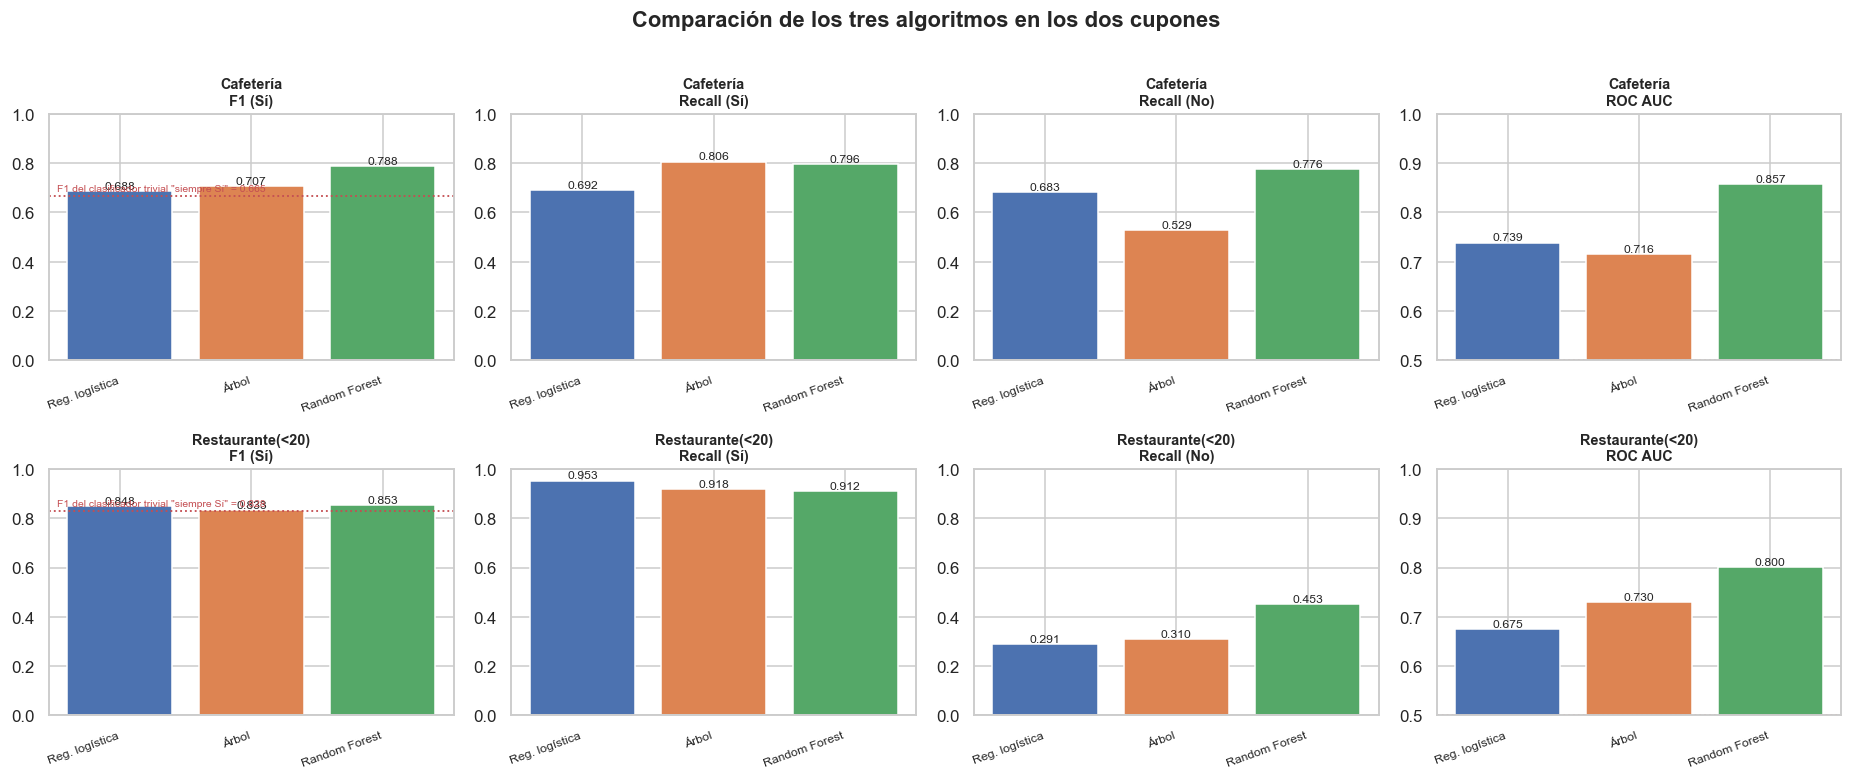

In [34]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for i, cup in enumerate(CUPONES):
    sub = comparativa.loc[cup]
    base_si = DATOS[cup]['y_te'].mean()
    for j, (col, lim) in enumerate([('F1 (Sí)', (0, 1)), ('Recall (Sí)', (0, 1)),
                                    ('Recall (No)', (0, 1)), ('ROC AUC', (0.5, 1))]):
        a = axes[i, j]
        v = sub[col]
        colores = ['#4c72b0', '#dd8452', '#55a868']
        a.bar(range(len(v)), v, color=colores)
        a.set_xticks(range(len(v)))
        a.set_xticklabels([m.replace(' de decisión', '').replace('Regresión ', 'Reg. ')
                           for m in v.index], rotation=20, ha='right', fontsize=8)
        a.set_ylim(*lim); a.set_title(f'{cup}\n{col}', fontsize=9.5)
        for k, x in enumerate(v):
            a.text(k, x, f'{x:.3f}', ha='center', va='bottom', fontsize=8)
        if col == 'F1 (Sí)':
            trivial = 2*base_si/(base_si+1)
            a.axhline(trivial, color='r', ls=':', lw=1.2)
            a.text(0.02, trivial+0.02, f'F1 del clasificador trivial "siempre Sí" = {trivial:.3f}',
                   transform=a.get_yaxis_transform(), fontsize=6.8, color='r')
        if col == 'ROC AUC':
            a.axhline(0.5, color='r', ls=':', lw=1.2)
plt.suptitle('Comparación de los tres algoritmos en los dos cupones', fontweight='bold', y=1.01)
plt.show()

### Argumentación de la selección

**En ambos cupones el mejor modelo es Random Forest**, y lo es de forma consistente en las tres
métricas de selección (F1 sobre prueba, ROC AUC y F1 por validación cruzada), lo que descarta que sea
un artefacto de la partición.

| Cupón | Modelo seleccionado | F1 (Sí) | ROC AUC | Margen sobre el segundo |
|:---|:---|---:|---:|:---|
| Cafetería | Random Forest | **0,7876** | **0,8573** | +0,080 de F1 sobre el árbol |
| Restaurante(<20) | Random Forest | **0,8531** | **0,8004** | +0,005 de F1, pero **+0,126 de AUC** sobre la logística |

**Por qué gana Random Forest.** La relación entre estas variables y la aceptación no es lineal ni
aditiva: el efecto de la hora depende del destino, el de la vigencia del cupón depende de la
distancia. La regresión logística solo puede capturar efectos aditivos en el *log-odds*, y un árbol
individual podado a profundidad 3 o 5 tiene demasiada poca capacidad. Random Forest combina muchos
árboles profundos y captura esas interacciones sin la varianza de uno solo.

**El caso de Restaurante(<20) merece una lectura cuidadosa, porque las métricas engañan.** La
regresión logística alcanza un F1 de 0,8483, apenas 0,005 por debajo del Random Forest, y un recall
sobre `Sí` de **0,9531**, el más alto de los tres. A primera vista parecería competitiva. Pero:

* su **recall sobre la clase minoritaria es 0,2906**: detecta menos de un tercio de los rechazos;
* su **ROC AUC es 0,6747**, muy por debajo del 0,8004 del Random Forest.

Lo que ocurre es que la logística se aproxima al **clasificador trivial**: con una tasa base del
70,7 %, responder siempre `Sí` da un F1 de 0,828. Un F1 de 0,848 con recall de 0,95 y AUC de 0,67 es
el perfil de un modelo que **casi siempre dice `Sí`** y acierta porque la clase es frecuente, no
porque discrimine. El ROC AUC, que es insensible a la tasa base, lo revela de inmediato. Es la razón
por la que incluimos el AUC y el recall de la minoritaria junto a las tres métricas exigidas.

<a name="s9"></a>
## 9. Identificación de las variables más relevantes

Usamos dos medidas complementarias, porque cada una tiene un sesgo distinto:

1. **Importancia por impureza** (`feature_importances_` del Random Forest): mide cuánto reduce cada
   variable la impureza en las divisiones. Es rápida, pero **favorece sistemáticamente a las variables
   de alta cardinalidad**, porque tienen más puntos de corte posibles. `ocupacion`, con 25 categorías,
   es el caso de libro.
2. **Importancia por permutación** sobre la partición de prueba: mide cuánto empeora el desempeño al
   barajar una variable. No tiene ese sesgo de cardinalidad y se calcula sobre datos no vistos. La
   usamos como medida principal.

La calculamos sobre las **variables originales** —no sobre las columnas codificadas— pasando el
`Pipeline` completo a `permutation_importance`, de modo que al permutar `ocupacion` se barajan de
golpe sus 24 columnas *dummy*. Usamos `roc_auc` como métrica porque, al ser insensible al umbral,
discrimina mucho mejor entre variables que el F1 en el cupón desbalanceado.

In [35]:
def importancias(cupon):
    d  = DATOS[cupon]
    gs = MODELOS[(cupon, MEJORES[cupon])]
    pre = gs.best_estimator_.named_steps['preproceso']
    nombres_cod = [n.split('__', 1)[1] for n in pre.get_feature_names_out()]

    # --- impureza, agregada por variable original ---
    def variable_origen(col):
        for v in sorted(d['X'].columns, key=len, reverse=True):
            if col == v or col.startswith(v + '_'):
                return v
        return col
    imp = pd.Series(gs.best_estimator_.named_steps['modelo'].feature_importances_,
                    index=nombres_cod)
    impureza = imp.groupby([variable_origen(c) for c in nombres_cod]).sum()

    # --- permutación sobre las variables originales ---
    pi = permutation_importance(gs.best_estimator_, d['X_te'], d['y_te'],
                                n_repeats=15, random_state=RANDOM_STATE,
                                scoring='roc_auc', n_jobs=N_JOBS)

    t = pd.DataFrame({'impureza': impureza,
                      'permutación': pd.Series(pi.importances_mean, index=d['X'].columns),
                      'desv_perm': pd.Series(pi.importances_std, index=d['X'].columns)})
    t['% impureza'] = (t.impureza / t.impureza.sum() * 100).round(2)
    t['tipo'] = ['demográfica' if v in DEMOGRAFICAS else 'contexto/hábito' for v in t.index]
    return t.sort_values('permutación', ascending=False)

IMPORTANCIAS = {}
for cup in CUPONES:
    IMPORTANCIAS[cup] = importancias(cup)
    print(f'===== {cup} — modelo: {MEJORES[cup]} =====')
    display(IMPORTANCIAS[cup].round(4).style.format(
        {'impureza': '{:.4f}', 'permutación': '{:.4f}', 'desv_perm': '{:.4f}', '% impureza': '{:.2f}'})
        .background_gradient(cmap='Blues', subset=['permutación']))

===== Cafetería — modelo: Random Forest =====


,impureza,permutación,desv_perm,% impureza,tipo
frecuencia_cafeteria,0.1450,0.1811,0.0150,14.50,contexto/hábito
ocupacion,0.1507,0.0406,0.0022,15.07,demográfica
vigencia_cupon,0.0423,0.0296,0.0079,4.23,contexto/hábito
destino,0.0320,0.0242,0.0073,3.20,contexto/hábito
ingreso,0.0681,0.0233,0.0024,6.81,demográfica
hora,0.0506,0.0213,0.0054,5.06,contexto/hábito
estado_civil,0.0420,0.0151,0.0021,4.20,demográfica
edad,0.0622,0.0146,0.0022,6.22,demográfica
educacion,0.0497,0.0143,0.0014,4.97,demográfica
frecuencia_bar,0.0462,0.0139,0.0020,4.62,contexto/hábito


===== Restaurante(<20) — modelo: Random Forest =====


,impureza,permutación,desv_perm,% impureza,tipo
vigencia_cupon,0.0454,0.0363,0.0094,4.54,contexto/hábito
ocupacion,0.1544,0.0178,0.0051,15.44,demográfica
hora,0.0665,0.0162,0.0084,6.65,contexto/hábito
destino,0.0372,0.0151,0.0058,3.72,contexto/hábito
educacion,0.0518,0.0138,0.0036,5.18,demográfica
clima,0.0413,0.0135,0.0051,4.13,contexto/hábito
ingreso,0.0753,0.0128,0.0038,7.53,demográfica
edad,0.0618,0.0127,0.0025,6.18,demográfica
frecuencia_comida_para_llevar,0.0493,0.0118,0.0027,4.93,contexto/hábito
frecuencia_cafeteria,0.0586,0.0109,0.0053,5.86,contexto/hábito


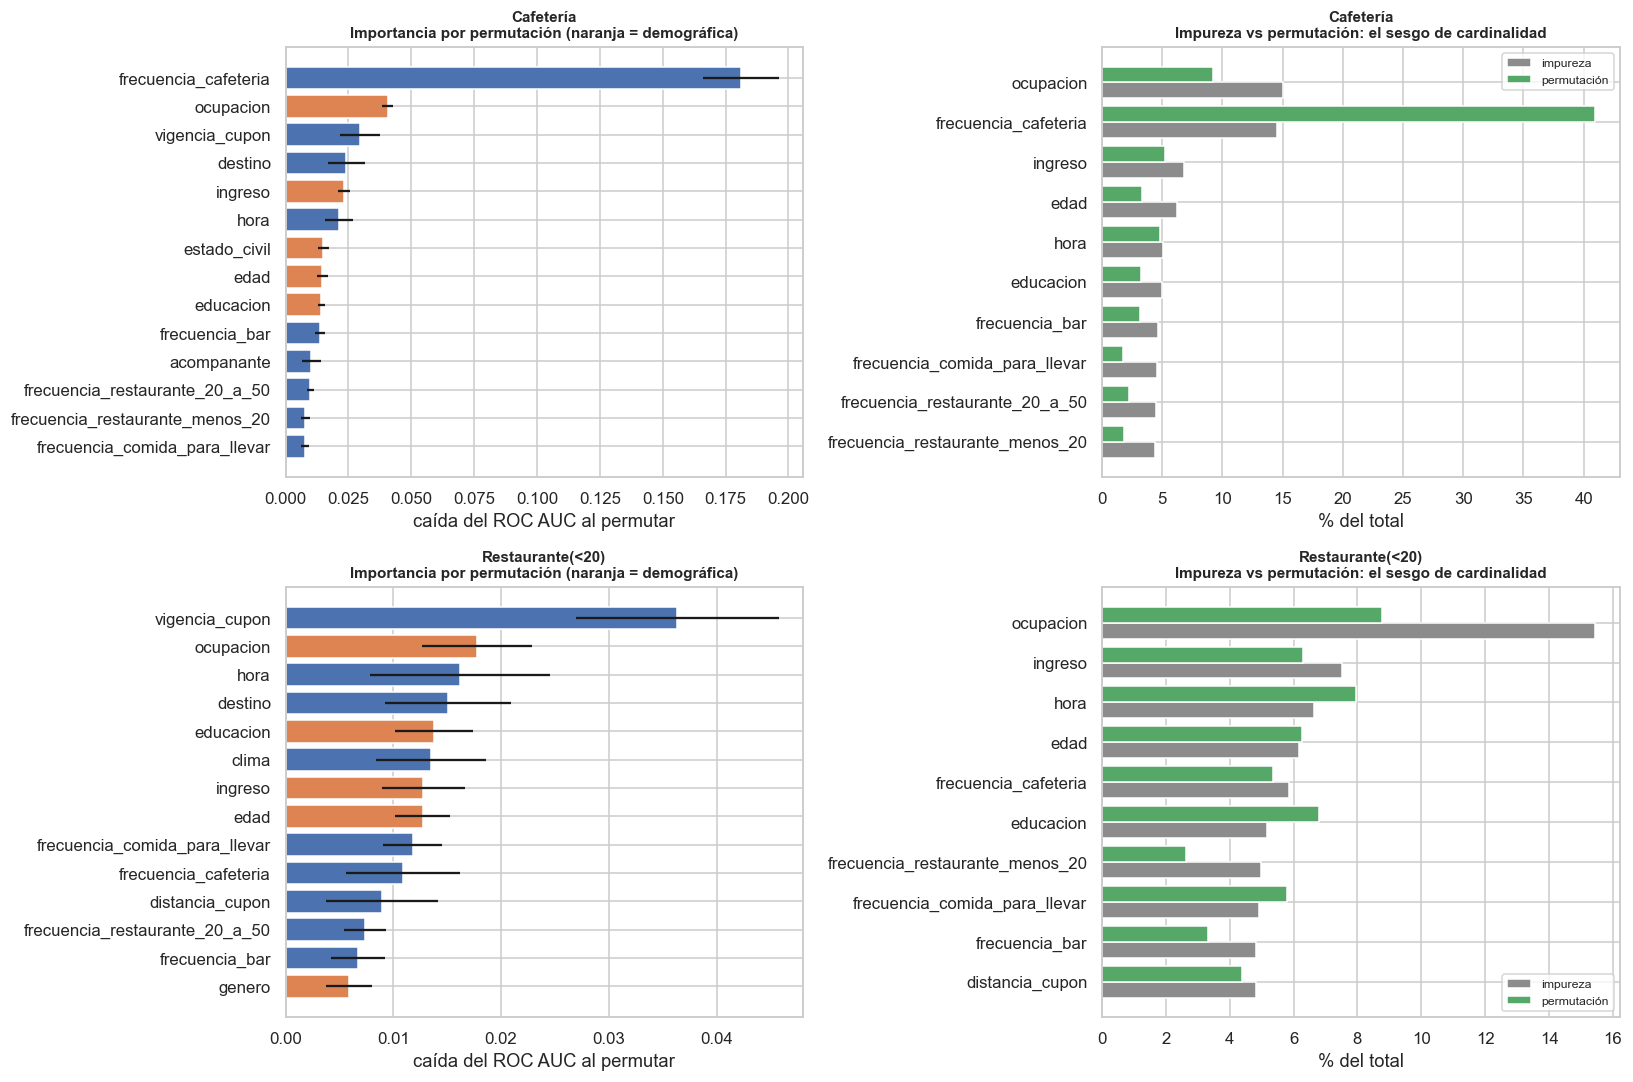

In [36]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for i, cup in enumerate(CUPONES):
    t = IMPORTANCIAS[cup]

    tt = t.head(14).iloc[::-1]
    colores = ['#dd8452' if x == 'demográfica' else '#4c72b0' for x in tt.tipo]
    axes[i, 0].barh(tt.index, tt['permutación'], xerr=tt.desv_perm, color=colores)
    axes[i, 0].set_xlabel('caída del ROC AUC al permutar')
    axes[i, 0].set_title(f'{cup}\nImportancia por permutación (naranja = demográfica)', fontsize=10)

    comp = t[['% impureza']].copy()
    comp['% permutación'] = (t['permutación'].clip(lower=0) /
                             t['permutación'].clip(lower=0).sum() * 100)
    comp = comp.sort_values('% impureza', ascending=False).head(10).iloc[::-1]
    y = np.arange(len(comp))
    axes[i, 1].barh(y - 0.2, comp['% impureza'], height=0.4, label='impureza', color='#8c8c8c')
    axes[i, 1].barh(y + 0.2, comp['% permutación'], height=0.4, label='permutación', color='#55a868')
    axes[i, 1].set_yticks(y); axes[i, 1].set_yticklabels(comp.index)
    axes[i, 1].legend(fontsize=8); axes[i, 1].set_xlabel('% del total')
    axes[i, 1].set_title(f'{cup}\nImpureza vs permutación: el sesgo de cardinalidad', fontsize=10)
plt.show()

In [37]:
# Peso de las variables demográficas frente a las de contexto y hábito
print('REPARTO DE LA IMPORTANCIA ENTRE TIPOS DE VARIABLE\n')
reparto = []
for cup in CUPONES:
    t = IMPORTANCIAS[cup]
    pos = t['permutación'].clip(lower=0)
    reparto.append({
        'Cupón': cup,
        '% impureza demográficas'   : t[t.tipo == 'demográfica']['% impureza'].sum().round(1),
        '% impureza contexto'       : t[t.tipo == 'contexto/hábito']['% impureza'].sum().round(1),
        '% permutación demográficas': round(pos[t.tipo == 'demográfica'].sum()/pos.sum()*100, 1),
        '% permutación contexto'    : round(pos[t.tipo == 'contexto/hábito'].sum()/pos.sum()*100, 1),
    })
display(pd.DataFrame(reparto).set_index('Cupón'))
print('Este reparto es el insumo cuantitativo para la discusión de sesgo de la sección 10.8:')
print('las variables demográficas concentran una fracción sustancial de la capacidad predictiva.')

REPARTO DE LA IMPORTANCIA ENTRE TIPOS DE VARIABLE



,% impureza demográficas,% impureza contexto,% permutación demográficas,% permutación contexto
Cupón,,,,
Cafetería,41.4,58.6,27.4,72.6
Restaurante(<20),43.0,57.0,32.4,67.6


Este reparto es el insumo cuantitativo para la discusión de sesgo de la sección 10.8:
las variables demográficas concentran una fracción sustancial de la capacidad predictiva.


In [38]:
# ---- Coeficientes de la regresión logística: dirección del efecto ----
print('DIRECCIÓN DEL EFECTO según la regresión logística (coeficientes en log-odds)')
print('Positivo = aumenta la probabilidad de aceptar; negativo = la reduce.\n')
for cup in CUPONES:
    gs = MODELOS[(cup, 'Regresión logística')]
    nombres = [n.split('__', 1)[1]
               for n in gs.best_estimator_.named_steps['preproceso'].get_feature_names_out()]
    co_ = pd.Series(gs.best_estimator_.named_steps['modelo'].coef_[0], index=nombres)
    top = co_.reindex(co_.abs().sort_values(ascending=False).index).head(12)
    print(f'--- {cup} ---')
    display(top.to_frame('coeficiente').style.format('{:+.3f}')
            .background_gradient(cmap='RdYlGn', vmin=-1, vmax=1))

DIRECCIÓN DEL EFECTO según la regresión logística (coeficientes en log-odds)
Positivo = aumenta la probabilidad de aceptar; negativo = la reduce.

--- Cafetería ---


,coeficiente
frecuencia_cafeteria,+0.957
vigencia_cupon_2 horas,-0.706
destino_Sin lugar urgente,+0.706
misma_direccion_Sí,+0.487
ocupacion_Profesionales y Técnicos de la Salud,+0.476
hora,-0.385
acompanante_Solo,-0.365
ocupacion_Arquitectura e Ingeniería,+0.341
ocupacion_Transporte y Manejo de Materiales,+0.325
acompanante_Hijo(s),-0.315


--- Restaurante(<20) ---


,coeficiente
clima_Soleado,+0.617
destino_Sin lugar urgente,+0.370
distancia_cupon,-0.061
hora,+0.000
edad,+0.000
educacion,+0.000
frecuencia_cafeteria,+0.000
frecuencia_comida_para_llevar,+0.000
frecuencia_bar,+0.000
ingreso,+0.000


In [39]:
# ---- Reglas del árbol de decisión: interpretabilidad directa ----
for cup in CUPONES:
    gs = MODELOS[(cup, 'Árbol de decisión')]
    arbol = gs.best_estimator_.named_steps['modelo']
    nombres = [n.split('__', 1)[1]
               for n in gs.best_estimator_.named_steps['preproceso'].get_feature_names_out()]
    print('=' * 95)
    print(f'{cup} — árbol de profundidad {arbol.get_depth()}, {arbol.get_n_leaves()} hojas')
    print(f'Codificación ordinal: frecuencias 0=nunca 1=menos de 1 2=(1 a 3) 3=(4 a 8) 4=más de 8')
    print('=' * 95)
    print(export_text(arbol, feature_names=nombres, max_depth=3, decimals=2,
                      class_names=['No', 'Sí'], show_weights=False))

Cafetería — árbol de profundidad 3, 8 hojas
Codificación ordinal: frecuencias 0=nunca 1=menos de 1 2=(1 a 3) 3=(4 a 8) 4=más de 8
|--- frecuencia_cafeteria <= 0.50
|   |--- ingreso <= 5.50
|   |   |--- ocupacion_Computación y Matemáticas <= 0.50
|   |   |   |--- class: No
|   |   |--- ocupacion_Computación y Matemáticas >  0.50
|   |   |   |--- class: No
|   |--- ingreso >  5.50
|   |   |--- ocupacion_Arquitectura e Ingeniería <= 0.50
|   |   |   |--- class: No
|   |   |--- ocupacion_Arquitectura e Ingeniería >  0.50
|   |   |   |--- class: Sí
|--- frecuencia_cafeteria >  0.50
|   |--- frecuencia_cafeteria <= 1.50
|   |   |--- destino_Sin lugar urgente <= 0.50
|   |   |   |--- class: No
|   |   |--- destino_Sin lugar urgente >  0.50
|   |   |   |--- class: Sí
|   |--- frecuencia_cafeteria >  1.50
|   |   |--- vigencia_cupon_2 horas <= 0.50
|   |   |   |--- class: Sí
|   |   |--- vigencia_cupon_2 horas >  0.50
|   |   |   |--- class: Sí

Restaurante(<20) — árbol de profundidad 5, 15 hoj

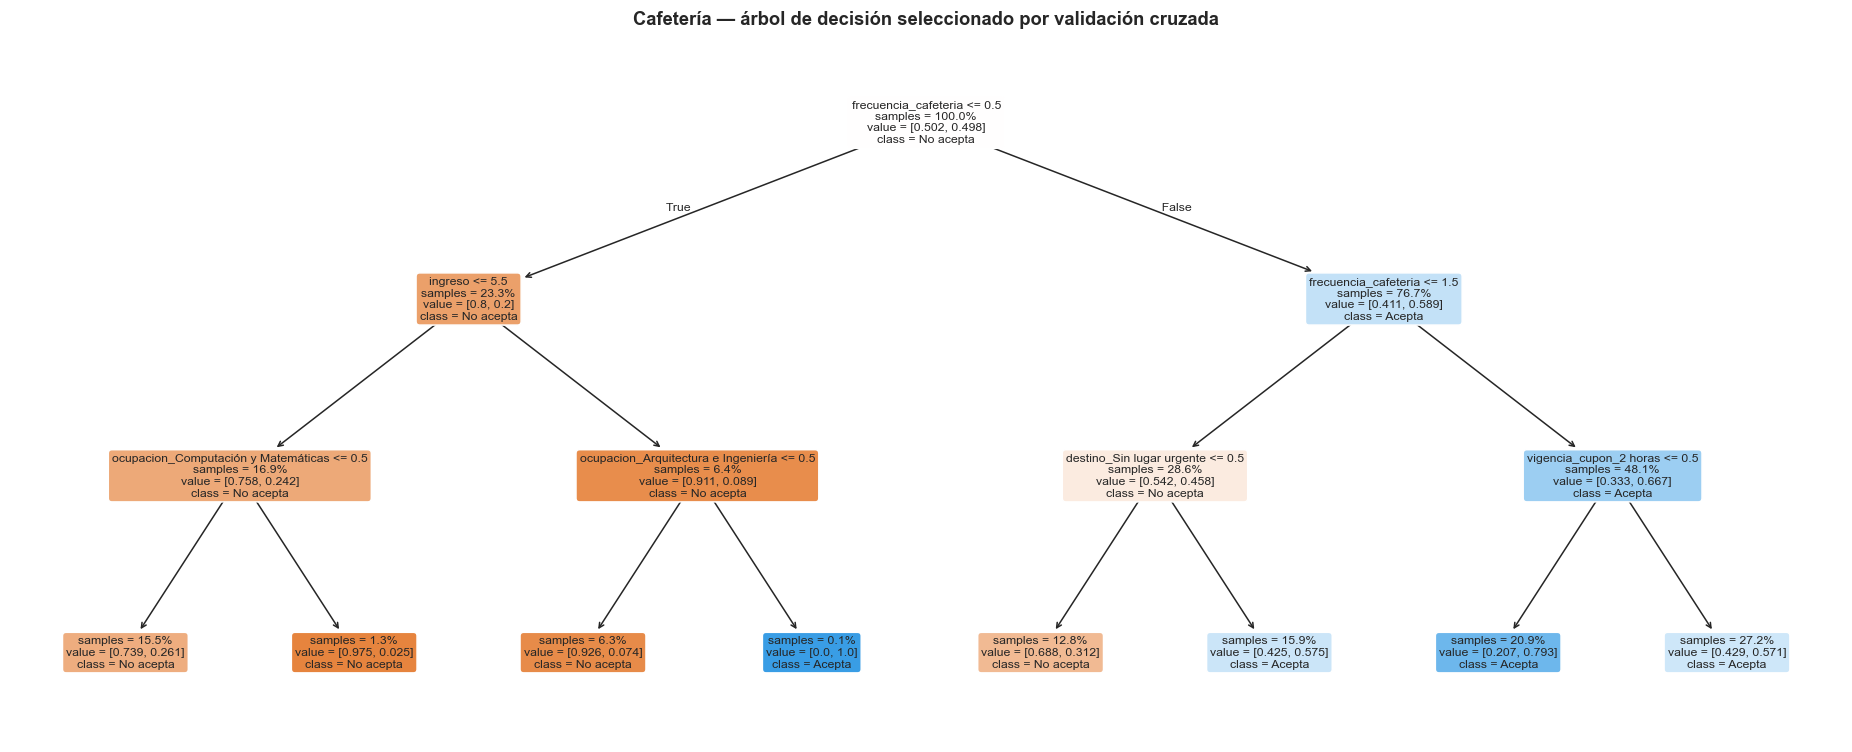

In [40]:
cup = 'Cafetería'
gs = MODELOS[(cup, 'Árbol de decisión')]
nombres = [n.split('__', 1)[1]
           for n in gs.best_estimator_.named_steps['preproceso'].get_feature_names_out()]
fig, ax = plt.subplots(figsize=(17, 7))
plot_tree(gs.best_estimator_.named_steps['modelo'], feature_names=nombres,
          class_names=['No acepta', 'Acepta'], filled=True, rounded=True,
          fontsize=8, max_depth=3, impurity=False, proportion=True, ax=ax)
ax.set_title(f'{cup} — árbol de decisión seleccionado por validación cruzada',
             fontweight='bold')
plt.show()

<a name="s10"></a>
## 10. Análisis de resultados

Esta sección responde las ocho preguntas del enunciado. Antes, dos cálculos que se citan varias veces.

In [41]:
print('REFERENCIAS PARA EL ANÁLISIS')
print('=' * 88)
for cup in CUPONES:
    d = DATOS[cup]
    base = d['y_te'].mean()
    f1_trivial = 2*base/(base + 1)          # F1 de responder siempre "Sí"
    mejor = comparativa.loc[(cup, MEJORES[cup])]
    print(f'\n{cup}:')
    print(f'  Tasa base de aceptación en prueba          : {base*100:.2f} %')
    print(f'  F1 del clasificador trivial "siempre Sí"   : {f1_trivial:.4f}')
    print(f'  F1 del mejor modelo ({MEJORES[cup]})        : {mejor["F1 (Sí)"]:.4f}')
    print(f'  Ganancia sobre el trivial                  : {mejor["F1 (Sí)"]-f1_trivial:+.4f}')
    print(f'  ROC AUC del mejor modelo                   : {mejor["ROC AUC"]:.4f}')

print('\n' + '=' * 88)
print('Hiperparámetros elegidos por validación cruzada:')
for (cup, alg), gs in MODELOS.items():
    print(f'  {cup:18s} {alg:22s} '
          f'{ {k.replace("modelo__",""): v for k, v in gs.best_params_.items()} }')

REFERENCIAS PARA EL ANÁLISIS

Cafetería:
  Tasa base de aceptación en prueba          : 49.85 %
  F1 del clasificador trivial "siempre Sí"   : 0.6653
  F1 del mejor modelo (Random Forest)        : 0.7876
  Ganancia sobre el trivial                  : +0.1223
  ROC AUC del mejor modelo                   : 0.8573

Restaurante(<20):
  Tasa base de aceptación en prueba          : 70.71 %
  F1 del clasificador trivial "siempre Sí"   : 0.8284
  F1 del mejor modelo (Random Forest)        : 0.8531
  Ganancia sobre el trivial                  : +0.0247
  ROC AUC del mejor modelo                   : 0.8004

Hiperparámetros elegidos por validación cruzada:
  Cafetería          Regresión logística    {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}
  Restaurante(<20)   Regresión logística    {'C': 0.01, 'penalty': 'l1', 'solver': 'liblinear'}
  Cafetería          Árbol de decisión      {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1}
  Restaurante(<20)   Árbol de decisión      {'crite

In [42]:
# Cuántos coeficientes mantuvo la regresión logística en cada cupón
print('¿Cuántas variables usa realmente cada regresión logística?\n')
for cup in CUPONES:
    gs = MODELOS[(cup, 'Regresión logística')]
    coefs = gs.best_estimator_.named_steps['modelo'].coef_[0]
    p = gs.best_params_
    print(f'{cup:18s} penalty={p["modelo__penalty"]}, C={p["modelo__C"]}, '
          f'solver={p["modelo__solver"]}')
    print(f'{"":18s} coeficientes NO nulos: {(coefs != 0).sum()} de {len(coefs)}')

¿Cuántas variables usa realmente cada regresión logística?

Cafetería          penalty=l2, C=0.1, solver=lbfgs
                   coeficientes NO nulos: 50 de 50
Restaurante(<20)   penalty=l1, C=0.01, solver=liblinear
                   coeficientes NO nulos: 3 de 50


### 10.1 ¿Qué características del contexto de conducción o del perfil del conductor parecen estar más relacionadas con la aceptación de cada tipo de cupón?

Las tres fuentes de evidencia —V de Cramér (asociación marginal), importancia por permutación
(contribución única dentro del Random Forest) y coeficientes de la logística (dirección del efecto)—
coinciden en el diagnóstico.

**Cafetería: el hábito de consumo manda.**

| Variable | V de Cramér | Permutación | Coef. logístico | Lectura |
|:---|---:|---:|---:|:---|
| `frecuencia_cafeteria` | **0,3779** | **0,1811** | **+0,957** | Quien ya visita cafeterías acepta el cupón de cafetería |
| `destino` (Sin lugar urgente) | 0,1853 | 0,0242 | +0,706 | Sin prisa, hay disposición a desviarse |
| `vigencia_cupon` (2 horas) | 0,1508 | 0,0296 | **−0,706** | Una vigencia corta **reduce** la aceptación |
| `misma_direccion` (Sí) | 0,0293 | 0,0067 | +0,487 | Si está de camino, cuesta menos aceptar |
| `hora` (más tarde) | 0,1795 | 0,0213 | −0,385 | El café es un consumo de mañana |
| `acompanante` (Solo) | 0,1460 | 0,0102 | −0,365 | Ir acompañado favorece la parada social |

`frecuencia_cafeteria` es **4,5 veces más importante que la segunda variable** por permutación. Es una
**coincidencia directa entre el hábito declarado y la oferta**: el predictor más fuerte de que alguien
acepte un cupón de cafetería es que sea alguien que va a cafeterías.

**Restaurante(<20): manda el contexto del trayecto, no el perfil.**

| Variable | V de Cramér | Permutación | Coef. logístico |
|:---|---:|---:|---:|
| `vigencia_cupon` | 0,2661 | **0,0363** | — |
| distancia al establecimiento | **0,2955** | 0,0089 | −0,061 |
| `hora` | 0,2831 | 0,0162 | — |
| `clima` (Soleado) | 0,2768 | 0,0135 | **+0,617** |
| `destino` (Sin lugar urgente) | 0,2373 | 0,0151 | +0,370 |
| `frecuencia_restaurante_menos_20` | 0,0676 | 0,0053 | — |

Aquí **ninguna variable domina** y, sobre todo, **la simetría se rompe**: la frecuencia con que alguien
va a restaurantes económicos es uno de los predictores *más débiles* (0,0676 de V de Cramér, frente a
0,3779 de su equivalente en Cafetería). Lo que predice la aceptación son **condiciones del momento**:
cuánto dura el cupón, a qué distancia está el local, qué hora es, si hace sol y si el conductor va sin
prisa.

**Lectura conjunta para Ruta Alpes.** Los dos cupones requieren estrategias distintas:

* El cupón de **cafetería** debe dirigirse **según el perfil de hábitos** del conductor. La
  segmentación por frecuencia de visita a cafeterías es casi suficiente.
* El cupón de **restaurante económico** debe dirigirse **según el momento del trayecto**. Segmentar por
  perfil aporta poco; lo que importa es elegir bien *cuándo* y *dónde* se envía.

Un detalle operativo con valor inmediato: en los dos cupones, `vigencia_cupon = 2 horas` **reduce** la
aceptación (coeficiente −0,706 en Cafetería y la variable de mayor importancia por permutación en
Restaurante). Es una de las pocas variables que **Ruta Alpes controla directamente**. Ampliar la
vigencia a un día es una palanca accionable que no depende de predecir nada.

### 10.2 ¿Existen variables que podrían ser redundantes o poco informativas?

Sí, y las separamos en tres grupos según el tipo de problema.

**a) Redundancia estructural — verificada en la sección 2.4:**

* **`direccion_opuesta` es el complemento exacto de `misma_direccion`.** Correlación **−1,0000**, celdas
  cruzadas vacías, y **V de Cramér idéntica** con la etiqueta (0,0293 y 0,0732). Conservar ambas genera
  colinealidad perfecta. **Eliminada.**
* **Los tres indicadores de distancia son una escala ordinal anidada.** `>5 min` es constante; `>25
  min = Sí` implica `>15 min = Sí`. **Colapsados en una ordinal de tres niveles.**
* **`temperatura` es casi redundante con `clima`.** Lluvioso determina 55 °F y Nevado determina 30 °F.
  Solo aporta dentro de Soleado. La decisión de conservarla queda validada *a posteriori*: su
  importancia por permutación es de apenas 0,0045 y 0,0012, es decir, **no aportaba**.

**b) Variables sin información por construcción:**

* **`vehiculo`**: 99,15 % nula, y **100 % nula en el conjunto de prueba**. **Eliminada.**
* **`tiempo_cupon_mayor_5min`**: constante (`Sí` en las 12 664 filas). Varianza cero. **Eliminada.**
* **`cupon`**: constante dentro de cada subconjunto. **Eliminada.**

**c) Variables conservadas que resultaron poco informativas.** La permutación da valores
indistinguibles de cero —o negativos, lo que significa que permutarlas *mejoró* el modelo, señal
inequívoca de ruido:

| Variable | Permutación Cafetería | Permutación Restaurante(<20) |
|:---|---:|---:|
| `misma_direccion` | 0,0067 | **−0,0001** |
| `estado_civil` | 0,0151 | **−0,0022** |
| `temperatura` | 0,0045 | 0,0012 |
| `tiene_hijos` | 0,0058 | 0,0027 |
| **`genero`** | **0,0077** | **0,0059** |

**El caso de `genero` merece destacarse** porque tiene consecuencias que van más allá de lo técnico:
es una de las variables **menos informativas de todo el conjunto** en ambos cupones. El experimento de
la sección 10.8 lo confirma entrenando el modelo sin ella: el F1 se mueve **−0,0020 en Cafetería** y
**+0,0043 en Restaurante(<20)** —donde incluso mejora—. Es decir, eliminar un **atributo legalmente
protegido** no cuesta nada medible. Lo retomamos como recomendación concreta en 10.8.

**Un hallazgo adicional sobre la propia regresión logística de Restaurante(<20).** La validación
cruzada eligió `penalty='l1'` con `C=0.01`, una regularización tan agresiva que **dejó solo 3
coeficientes distintos de cero** de 49: `clima_Soleado` (+0,617), `destino_Sin lugar urgente` (+0,370)
y `distancia_cupon` (−0,061). El modelo descartó por sí solo el 94 % de las variables. Que aun así
alcance un F1 de 0,8483 no habla bien del modelo: habla de lo engañoso que es el F1 en una clase
mayoritaria del 70,7 %. Volvemos a esto en 10.3.

### 10.3 ¿El desempeño y el comportamiento de los modelos difieren entre Cafetería y Restaurante(<20)? ¿A qué atribuye esa diferencia?

**Sí, difieren mucho, y la comparación directa de F1 lleva a la conclusión equivocada.**

| Métrica | Cafetería | Restaurante(<20) | ¿Dónde parece mejor? |
|:---|---:|---:|:---|
| F1 (Sí) del mejor modelo | 0,7876 | **0,8531** | Restaurante |
| **ROC AUC** del mejor modelo | **0,8573** | 0,8004 | **Cafetería** |
| Recall de la clase `No` | **0,7756** | 0,4532 | **Cafetería** |
| F1 macro | **0,7859** | 0,6987 | **Cafetería** |
| Tasa base de `Sí` | 49,85 % | 70,71 % | — |
| F1 del clasificador trivial "siempre Sí" | 0,6653 | 0,8284 | — |
| **Ganancia del modelo sobre el trivial** | **+0,1223** | **+0,0247** | **Cafetería** |

**La diferencia de F1 es un artefacto de la tasa base, no una diferencia de calidad.** En
Restaurante(<20), responder siempre `Sí` ya produce un F1 de 0,8284. El mejor modelo llega a 0,8531:
**una ganancia de apenas 0,025**. En Cafetería, el trivial da 0,6653 y el modelo alcanza 0,7876: una
ganancia de **0,1223, cinco veces mayor**. Medido contra lo que cuesta no tener modelo, **el modelo de
Cafetería es claramente el más valioso**, justo al revés de lo que sugiere el F1 en bruto.

Las métricas insensibles a la tasa base lo confirman: el ROC AUC es 0,8573 en Cafetería frente a
0,8004, y el recall de la clase `No` es 0,7756 frente a 0,4532 — en Restaurante(<20) el modelo
**no detecta ni la mitad de los rechazos**.

**A qué atribuimos la diferencia. Tres causas, en orden de peso:**

1. **La existencia de una variable que "encaja" con la oferta (causa principal).** En Cafetería hay un
   predictor directo del comportamiento: `frecuencia_cafeteria`, con V de Cramér de 0,3779 y una
   importancia por permutación 4,5 veces superior a la de cualquier otra variable. En Restaurante(<20)
   el predictor equivalente —`frecuencia_restaurante_menos_20`— **falla** (0,0676). El modelo de
   Cafetería tiene una señal fuerte que aprender; el otro no.

2. **El desbalance reduce el margen de mejora.** Con el 70,7 % de aceptación, hay poca variabilidad que
   explicar: la mayoría acepta casi en cualquier circunstancia. Esto comprime el espacio en el que un
   modelo puede aportar y es la razón de que la ganancia sobre el trivial sea tan pequeña.

3. **La naturaleza del consumo.** Un cupón de restaurante económico tiene **barrera de entrada baja**:
   es un gasto pequeño que casi cualquiera acepta si pasa cerca. Un café es un consumo **más ligado al
   hábito personal y a la hora del día**. Esto explica por qué en Cafetería predice el *perfil* y en
   Restaurante(<20) predice el *contexto*. Encaja con el patrón de los cinco tipos de cupón observado
   en la sección 2.3: Comida para llevar (73,6 %) y Restaurante(<20) (70,7 %) se aceptan mucho; Bar
   (41,0 %) y Restaurante(20-50) (44,1 %), que implican más gasto y más compromiso, se rechazan más.

**Diferencias en el comportamiento de los algoritmos, no solo en el desempeño:**

* En **Cafetería** los tres algoritmos se ordenan con claridad (RF 0,7876 > árbol 0,7073 > logística
  0,6881) y Random Forest gana por un margen amplio: hay estructura no lineal que capturar.
* En **Restaurante(<20)** los tres quedan comprimidos entre 0,8333 y 0,8531 en F1, pero se separan
  mucho en AUC (0,6747 a 0,8004). Es decir: **tienen un F1 parecido por razones distintas**. La
  logística con L1 y `C=0.01` conservó 3 de 49 coeficientes y se comporta casi como el clasificador
  trivial (recall de `Sí` de 0,9531, recall de `No` de 0,2906, AUC de 0,6747), mientras el Random
  Forest sí discrimina.

> **Una limitación de nuestra propia metodología, que conviene declarar.** Elegimos `scoring='f1'` en
> `GridSearchCV` porque es la métrica con la que se califica la actividad 11. En Restaurante(<20) esa
> elección llevó a la rejilla a seleccionar una logística casi trivial, porque maximizar el F1 de la
> clase mayoritaria premia justamente eso. Con `scoring='roc_auc'` o `'f1_macro'` la logística habría
> quedado mejor configurada. Es un ejemplo concreto de cómo **la métrica de optimización determina el
> modelo que se obtiene**, y no solo cómo se lo evalúa.

### 10.4 ¿Aplicar balanceo de clases en Restaurante(<20) mejoró el modelo? Justifique considerando tanto el F1-score general como el recall de la clase minoritaria

**Sí mejoró, y la conclusión depende de cuál de las dos métricas se mire — que es precisamente el
punto de la pregunta.** Recordemos que **la clase minoritaria es `No`** (29,3 %), no `Sí`.

| Estrategia | F1 (Sí) | Recall (No) · minoritaria | F1 (No) | F1 macro | ROC AUC |
|:---|---:|---:|---:|---:|---:|
| Sin balanceo | 0,8531 | 0,4532 | 0,5444 | 0,6987 | 0,8004 |
| SMOTENC total (1:1) | 0,8414 | **0,5172** | 0,5660 | 0,7037 | 0,8020 |
| **SMOTENC parcial (0,6)** | **0,8544** | 0,4877 | **0,5673** | **0,7109** | 0,7978 |
| `class_weight='balanced'` | 0,8585 | 0,4532 | 0,5526 | 0,7055 | 0,7988 |

**Mirando solo el F1 general, la respuesta sería "casi no cambia".** SMOTENC total lo empeora
ligeramente (0,8531 → 0,8414, −0,012) y `class_weight` lo mejora algo (→ 0,8585). Ninguna variación es
grande.

**Mirando el recall de la clase minoritaria, la respuesta es que sí mejora, y de forma relevante.**
SMOTENC total lo lleva de 0,4532 a **0,5172**: una ganancia de 6,4 puntos, un **14 % relativo**. En
términos concretos, de los 203 rechazos de la partición de prueba el modelo sin balancear detecta 92 y
con SMOTENC detecta 105. Trece conductores más a los que no se envía una oferta que iban a rechazar.

**Las tres conclusiones que se desprenden:**

1. **El intercambio es real y es el esperado.** Balancear mueve la frontera de decisión hacia la clase
   minoritaria: se ganan rechazos detectados y se pierden algunas aceptaciones. El F1 macro, que pondera
   ambas clases por igual, sube en las tres estrategias, lo que indica que el cambio neto es favorable.

2. **El balanceo parcial domina al total.** `sampling_strategy=0.6` logra el **mejor F1 macro (0,7109)**
   y, a diferencia del balanceo completo, **no sacrifica F1 en la clase positiva** (0,8544 frente a
   0,8531). La razón es que el desbalance 71/29 es **moderado, no extremo**: forzar la paridad total
   sobrecorrige y genera más ejemplos sintéticos de los necesarios.

3. **`class_weight='balanced'` no sirve para este objetivo.** Produce el F1 más alto de los cuatro
   (0,8585) pero deja el recall de la minoritaria **exactamente igual** (0,4532). Es el ejemplo más
   claro de por qué el enunciado pide mirar las dos métricas: por F1 sería la mejor opción, y no
   resuelve en absoluto el problema que motivó la actividad.

**Un matiz importante sobre qué hace realmente el balanceo.** El ROC AUC se mantiene casi constante en
las cuatro estrategias (0,7978–0,8020). Como el AUC mide la capacidad de **ordenar** las observaciones
con independencia del umbral, esto demuestra que **el balanceo no hace al modelo más capaz de
distinguir** quién acepta y quién no: lo que hace es **reubicar el umbral de decisión** en un punto
operativo más equilibrado.

De ahí se sigue una recomendación práctica: **el mismo efecto se obtiene ajustando el umbral sobre las
probabilidades del modelo sin balancear**, sin generar ni un dato sintético. Es más simple, más
transparente y permite mover el punto de operación en producción sin reentrenar. SMOTENC es útil aquí
como diagnóstico —muestra que hay margen en la clase minoritaria— pero para producción recomendamos
calibrar el umbral.

**Recomendación final a Ruta Alpes:** aplicar **SMOTENC parcial (`sampling_strategy=0.6`)** si se
quiere un modelo entrenado ya equilibrado, o bien conservar el modelo sin balancear y **mover el umbral
de decisión**. La elección entre ambas depende de si se prefiere resolverlo en el entrenamiento o en el
despliegue. Lo que **no** recomendamos es `class_weight='balanced'`, que da la mejor métrica
superficial sin resolver el problema.

### 10.5 A partir de alguno de los modelos de árbol o Random Forest, describa las características que llevan a aceptar o rechazar un cupón. Incluya la utilidad y la limitación de este tipo de interpretación

**Las reglas del árbol de Cafetería** (profundidad 3, 8 hojas; en la codificación ordinal
0 = *nunca*, 1 = *menos de 1*, 2 = *1 a 3*, 3 = *4 a 8*, 4 = *más de 8*):

```
SI frecuencia_cafeteria = nunca (≤ 0,5)
   └─ RECHAZA, salvo un caso: si ingreso es alto (> 5,5, es decir ≥ $75.000)
      Y la ocupación es Arquitectura e Ingeniería → acepta
SI frecuencia_cafeteria = menos de 1 vez al mes (entre 0,5 y 1,5)
   ├─ y el destino NO es "sin lugar urgente" → RECHAZA
   └─ y el destino SÍ es "sin lugar urgente" → ACEPTA
SI frecuencia_cafeteria ≥ 1 a 3 veces al mes (> 1,5)
   └─ ACEPTA (la vigencia del cupón solo modula la confianza)
```

Leído en una frase: **la primera pregunta que hace el modelo es si la persona va a cafeterías.** Si
nunca va, rechaza casi siempre. Si va con alguna regularidad, acepta casi siempre. El contexto
—destino sin prisa, vigencia amplia— solo decide en la franja intermedia de quienes van *menos de una
vez al mes*.

**Las reglas del árbol de Restaurante(<20)** (profundidad 5, 15 hojas) son estructuralmente distintas:

```
SI la distancia al establecimiento es ≤ 25 min (≤ 1,5)
   ├─ y la vigencia es de 1 día → ACEPTA en casi todas las ramas
   └─ y la vigencia es de 2 horas → depende de la hora del día
SI la distancia es > 25 min (> 1,5)
   ├─ y es antes de las 6:00 p.m. (hora ≤ 3,5)
   │    ├─ y nunca va a bares → ACEPTA
   │    └─ y va a bares → RECHAZA
   └─ y es a las 10:00 p.m. (hora > 3,5) → RECHAZA
```

Aquí **no aparece ninguna variable de perfil en los primeros niveles**: la raíz es la distancia, y
después la vigencia y la hora. Confirma lo visto en 10.1 y 10.3: este cupón se decide por el contexto
del trayecto.

#### Utilidad de este tipo de interpretación

1. **Es comunicable a quien decide.** "Si el conductor no va nunca a cafeterías, no le envíes el cupón"
   es una regla que el equipo de producto de Ruta Alpes puede entender, discutir y aprobar sin saber
   nada de machine learning. Ningún conjunto de coeficientes logra eso.
2. **Es auditable, y eso permite detectar sesgo.** Al leer las reglas vemos que una de las ramas de
   Cafetería usa **`ingreso` y `ocupacion`** para decidir sobre quienes nunca van a cafeterías. Ese es
   exactamente el tipo de uso que la pregunta 10.8 señala como problemático, y **solo es visible porque
   el modelo es legible**. Un Random Forest de 500 árboles lo haría igual, pero sin dejarlo a la vista.
3. **Genera acción inmediata, no solo predicción.** La regla muestra que la vigencia de 2 horas
   perjudica, y la vigencia es una variable que la empresa controla. La interpretación convierte el
   modelo en una decisión de producto.
4. **Sirve de control de sensatez.** Las reglas son coherentes con lo que se esperaría del dominio
   (el hábito predice el consumo; la distancia y la prisa disuaden), lo que da confianza de que el
   modelo no está apoyado en un artefacto de los datos.

#### Limitaciones, que son serias

1. **La interpretabilidad cuesta desempeño.** El árbol legible de Cafetería obtiene F1 = 0,7073 frente
   a 0,7876 del Random Forest: **8 puntos de F1**. Las reglas que se pueden leer no son las del modelo
   que mejor predice. Hay que elegir, o usar cada uno para lo suyo.
2. **Los árboles son inestables.** Pequeños cambios en los datos de entrenamiento pueden producir un
   árbol con una raíz distinta y reglas distintas. Las reglas de arriba describen *un* árbol ajustado
   con `random_state=42`, no una verdad del fenómeno. Presentarlas a Ruta Alpes como "las reglas de
   negocio" sería excederse.
3. **La importancia por impureza engaña, y aquí lo medimos.** `ocupacion` aparece como **la variable
   más importante por impureza** en los dos cupones (15,07 % y 15,44 %), pero por permutación cae a
   0,0406 y 0,0178 —en Cafetería, menos de una cuarta parte de `frecuencia_cafeteria`—. La causa es su
   **cardinalidad**: con 25 categorías genera muchos más puntos de corte posibles y acumula reducciones
   de impureza espurias. Quien se guíe por `feature_importances_` concluiría que la ocupación del
   conductor es el factor decisivo. **No lo es.**
4. **Una regla no es una relación causal.** Que el árbol divida por `ingreso` no significa que subir el
   ingreso de alguien lo haga aceptar cupones. Son correlaciones en una encuesta, y usarlas como si
   fueran causas es el error que lleva a intervenciones que no funcionan.
5. **Cada observación recorre una sola rama.** El árbol no muestra el efecto conjunto de variables que
   quedan en ramas distintas, y al leer una regla concreta se pierde de vista que solo aplica al
   subgrupo que llegó a ese nodo —que puede ser muy pequeño.
6. **El techo del ruido.** Las 23 combinaciones con etiquetas contradictorias (H4) implican que ninguna
   regla puede ser perfecta. Un árbol que las separase estaría memorizando, no aprendiendo.

### 10.6 ¿Cómo podría integrarse este tipo de modelo en una aplicación de conducción para decidir en tiempo real qué cupón mostrar?

**Lo primero: el problema de negocio no es el que resolvimos.** Entrenamos clasificadores binarios que
responden *"¿aceptará este cupón?"*. La aplicación necesita responder *"¿cuál de los cupones
disponibles conviene mostrar, si alguno?"*. Son preguntas distintas, y el puente es usar la
**probabilidad** en lugar de la clase.

**Arquitectura propuesta:**

1. **No usar `predict()`, usar `predict_proba()`.** `predict` aplica un umbral fijo de 0,5 que no tiene
   nada que ver con los objetivos del negocio. Con la probabilidad se puede **ordenar** los cupones
   candidatos y aplicar un umbral calibrado según cuánto cuesta una notificación irrelevante.
2. **Un modelo por tipo de cupón, y decisión por comparación.** Con los cinco tipos modelados, ante un
   trayecto se evalúan todos, se ordenan por probabilidad y se muestra el mejor **solo si supera el
   umbral**. "No mostrar nada" debe ser una salida válida y frecuente: el enunciado señala que las
   notificaciones irrelevantes generan molestia, y un sistema que siempre muestra algo garantiza
   molestar.
3. **Separar las variables por su disponibilidad en el momento de la inferencia**, que es la
   restricción de ingeniería que decide si esto es viable:

   | Origen | Variables | Disponibilidad |
   |:---|:---|:---|
   | Contexto del trayecto | `destino`, `hora`, `clima`, `temperatura`, distancia, `misma_direccion` | **En tiempo real**: GPS, ruta activa, API de clima |
   | Oferta | `cupon`, `vigencia_cupon` | **Las define la aplicación**: son palancas, no datos |
   | Perfil | `genero`, `edad`, `estado_civil`, `tiene_hijos`, `educacion`, `ocupacion`, `ingreso` | Del registro; estáticas y **sensibles** (ver 10.7 y 10.8) |
   | Hábitos | las cinco `frecuencia_*` | Hoy **autodeclaradas en una encuesta**; deberían derivarse del comportamiento observado en la app |
   | Acompañantes | `acompanante` | **El punto débil**: la app no sabe quién va en el coche |

   Dos consecuencias prácticas. Primera: `acompanante` no es observable en producción, así que el
   modelo desplegado debería entrenarse sin ella o inferirla, y su importancia (0,0102 y 0,0041) indica
   que **prescindir de ella cuesta muy poco**. Segunda: `frecuencia_cafeteria` es la variable más
   predictiva de Cafetería y hoy proviene de una encuesta. **Sustituirla por la frecuencia real
   observada en la app es la mejora de mayor impacto posible**, y Ruta Alpes ya tiene esos datos.

4. **Latencia.** El Random Forest de 500 árboles predice una fila en pocos milisegundos; el cuello de
   botella es construir las variables (consulta de clima, cálculo de ruta), no el modelo. Conviene
   precalcular el perfil y los hábitos, y cachear el clima por zona y franja.
5. **Reglas de negocio por encima del modelo.** Límite de notificaciones por trayecto y por día, nunca
   notificar en maniobras exigentes, respetar el modo "no molestar". **La seguridad vial y la
   experiencia están por encima de la tasa de conversión**, y eso se implementa como restricción
   externa, no confiando en que el modelo lo aprenda.
6. **Medición honesta: A/B testing.** El F1 offline no mide el resultado de negocio. Hay que comparar
   contra la política actual con asignación aleatoria y medir conversión, molestia (desactivaciones,
   notificaciones descartadas) y retención.
7. **Monitoreo y reentrenamiento.** Vigilar deriva en la distribución de las variables y caída de la
   conversión; reentrenar periódicamente con el comportamiento observado.

> **El riesgo más importante de esta arquitectura: el bucle de retroalimentación.** Una vez desplegado,
> el modelo **solo observa el resultado de los cupones que decidió mostrar**. Si deja de mostrar
> cupones de cafetería a quienes declaran no ir nunca, nunca obtendrá evidencia de que algunos los
> habrían aceptado, y la creencia inicial se vuelve **autoconfirmante**. La mitigación estándar es
> reservar una fracción del tráfico (5–10 %) a decisiones aleatorias o exploratorias, de modo que el
> sistema siga recogiendo datos sobre lo que descarta. Sin eso, el modelo se degrada sin que las
> métricas lo muestren.

In [43]:
# ============================================================
# Auditoría de equidad: ¿el modelo se comporta igual en todos los grupos?
# Insumo cuantitativo para las preguntas 10.7 y 10.8
# ============================================================
def auditoria_equidad(cupon, atributo):
    d  = DATOS[cupon]
    gs = MODELOS[(cupon, MEJORES[cupon])]
    pred = gs.predict(d['X_te'])
    prob = gs.predict_proba(d['X_te'])[:, 1]

    filas = []
    for g, idx in d['X_te'].groupby(atributo, observed=True).groups.items():
        pos = d['X_te'].index.get_indexer(idx)
        yv, pv, pb = d['y_te'].iloc[pos], pred[pos], prob[pos]
        if len(yv) < 30 or yv.nunique() < 2:
            continue
        filas.append({
            'grupo': str(g), 'n': len(yv),
            'tasa real de aceptación': yv.mean(),
            'tasa que el modelo predice': (pv == 1).mean(),
            'recall (Sí)': recall_score(yv, pv, zero_division=0),
            'precisión (Sí)': precision_score(yv, pv, zero_division=0),
            'recall (No)': recall_score(yv, pv, pos_label=0, zero_division=0),
            'ROC AUC': roc_auc_score(yv, pb),
        })
    t = pd.DataFrame(filas).set_index('grupo')
    t['brecha predicha - real'] = t['tasa que el modelo predice'] - t['tasa real de aceptación']
    return t

for cup in CUPONES:
    print('=' * 100); print(f'{cup} — modelo {MEJORES[cup]}')
    for attr in ['genero', 'edad', 'ingreso']:
        t = auditoria_equidad(cup, attr)
        if len(t) < 2:
            continue
        print(f'\n--- por {attr} ---')
        display(t.round(4))
        print(f'    Dispersión del recall (Sí) entre grupos : '
              f'{t["recall (Sí)"].max() - t["recall (Sí)"].min():.4f}')
        print(f'    Dispersión del ROC AUC entre grupos     : '
              f'{t["ROC AUC"].max() - t["ROC AUC"].min():.4f}')

Cafetería — modelo Random Forest



--- por genero ---


,n,tasa real de aceptación,tasa que el modelo predice,recall (Sí),precisión (Sí),recall (No),ROC AUC,brecha predicha - real
grupo,,,,,,,,
Femenino,503,0.4911,0.5070,0.7976,0.7725,0.7734,0.8598,0.0159
Masculino,492,0.5061,0.5122,0.7952,0.7857,0.7778,0.8544,0.0061


    Dispersión del recall (Sí) entre grupos : 0.0024
    Dispersión del ROC AUC entre grupos     : 0.0054



--- por edad ---


...

,n,tasa real de aceptación,tasa que el modelo predice,recall (Sí),precisión (Sí),recall (No),ROC AUC,brecha predicha - real
grupo,,,,,,,,
21,122,0.7869,0.8607,0.9375,0.8571,0.4231,0.7871,0.0738
26,143,0.7413,0.8042,0.8962,0.8261,0.4595,0.7746,0.0629
31,109,0.7523,0.7798,0.8171,0.7882,0.3333,0.7082,0.0275
36,75,0.6133,0.7600,0.9130,0.7368,0.4828,0.8677,0.1467
41,68,0.6176,0.8676,1.0000,0.7119,0.3462,0.8045,0.2500
46,36,0.8333,0.8889,0.9333,0.8750,0.3333,0.8611,0.0556
50 o más,102,0.6078,0.7059,0.9355,0.8056,0.6500,0.8895,0.0980
menor de 21,38,0.6842,0.8684,0.9615,0.7576,0.3333,0.6987,0.1842


    Dispersión del recall (Sí) entre grupos : 0.1829
    Dispersión del ROC AUC entre grupos     : 0.1908



--- por ingreso ---


,n,tasa real de aceptación,tasa que el modelo predice,recall (Sí),precisión (Sí),recall (No),ROC AUC,brecha predicha - real
grupo,,,,,,,,
$100.000 o más,88,0.7727,0.7614,0.8382,0.8507,0.5000,0.8132,-0.0114
$12.500 - $24.999,91,0.7033,0.8901,0.9844,0.7778,0.3333,0.7920,0.1868
$25.000 - $37.499,112,0.7946,0.9286,0.9888,0.8462,0.3043,0.7785,0.1339
$37.500 - $49.999,99,0.6061,0.7071,0.8333,0.7143,0.4872,0.7502,0.1010
$50.000 - $62.499,84,0.8452,0.7976,0.8732,0.9254,0.6154,0.8342,-0.0476
$62.500 - $74.999,48,0.7083,0.8750,1.0000,0.8095,0.4286,0.8666,0.1667
$75.000 - $87.499,49,0.5714,0.7551,0.8929,0.6757,0.4286,0.7534,0.1837
$87.500 - $99.999,53,0.5660,0.6226,0.8000,0.7273,0.6087,0.7899,0.0566
Menos de $12.500,69,0.6667,0.8261,0.9565,0.7719,0.4348,0.8091,0.1594


    Dispersión del recall (Sí) entre grupos : 0.2000
    Dispersión del ROC AUC entre grupos     : 0.1164


In [44]:
# ============================================================
# ¿Cuánto cuesta renunciar a las variables demográficas?
# Tres escenarios, para que la recomendación de 10.8 tenga respaldo numérico
# y no sea una afirmación cómoda.
# ============================================================
ESCENARIOS = {
    'A. Todas las variables'      : set(),
    'B. Sin género'               : {'genero'},
    'C. Sin ninguna demográfica'  : set(DEMOGRAFICAS),
}

def entrenar_excluyendo(cupon, excluir):
    d = DATOS[cupon]
    params = {k.replace('modelo__', ''): v
              for k, v in MODELOS[(cupon, MEJORES[cupon])].best_params_.items()}

    ord_ = [c for c in ORDINALES if c not in excluir]
    nom_ = [c for c in NOMINALES if c not in excluir]
    num_ = [c for c in NUMERICAS if c not in excluir]

    bloques = []
    if ord_:
        bloques.append(('ord', Pipeline([
            ('cod', OrdinalEncoder(categories=[ORDENES[c] for c in ord_],
                                   handle_unknown='use_encoded_value', unknown_value=np.nan,
                                   encoded_missing_value=np.nan)),
            ('imp', SimpleImputer(strategy='most_frequent'))]), ord_))
    if num_:
        bloques.append(('num', Pipeline([('imp', SimpleImputer(strategy='median'))]), num_))
    if nom_:
        bloques.append(('nom', Pipeline([
            ('imp', SimpleImputer(strategy='most_frequent')),
            ('oh', OneHotEncoder(categories=[sorted(d['X_tr'][c].dropna().unique().tolist())
                                             for c in nom_],
                                 handle_unknown='ignore', drop='first'))]), nom_))

    pipe = Pipeline([('preproceso', ColumnTransformer(bloques)),
                     ('modelo', RandomForestClassifier(random_state=RANDOM_STATE,
                                                       n_jobs=-1, **params))])
    pipe.fit(d['X_tr'], d['y_tr'])
    pred = pipe.predict(d['X_te']); prob = pipe.predict_proba(d['X_te'])[:, 1]
    return {'nº variables': len(ord_) + len(num_) + len(nom_),
            'F1 (Sí)': f1_score(d['y_te'], pred),
            'Recall (No)': recall_score(d['y_te'], pred, pos_label=0),
            'ROC AUC': roc_auc_score(d['y_te'], prob)}

print('EXPERIMENTO: ¿cuánto cuesta renunciar a las variables demográficas?\n')
etica = []
for cup in CUPONES:
    for nombre, excluir in ESCENARIOS.items():
        r = entrenar_excluyendo(cup, excluir)
        r.update({'Cupón': cup, 'Escenario': nombre})
        etica.append(r)

tabla_etica = pd.DataFrame(etica).set_index(['Cupón', 'Escenario'])
display(tabla_etica.round(4))

print('\nCosto respecto al escenario A (todas las variables):\n')
costos = []
for cup in CUPONES:
    ref = tabla_etica.loc[(cup, 'A. Todas las variables')]
    for esc in ['B. Sin género', 'C. Sin ninguna demográfica']:
        fila = tabla_etica.loc[(cup, esc)]
        costos.append({'Cupón': cup, 'Escenario': esc,
                       'Δ F1 (Sí)': fila['F1 (Sí)'] - ref['F1 (Sí)'],
                       'Δ Recall (No)': fila['Recall (No)'] - ref['Recall (No)'],
                       'Δ ROC AUC': fila['ROC AUC'] - ref['ROC AUC']})
display(pd.DataFrame(costos).set_index(['Cupón', 'Escenario']).round(4)
        .style.format('{:+.4f}').background_gradient(cmap='RdYlGn', vmin=-0.12, vmax=0.12))

EXPERIMENTO: ¿cuánto cuesta renunciar a las variables demográficas?



nº variables  F1 (Sí)  Recall (No)  ROC AUC
Cupón            Escenario                                                              
Cafetería        A. Todas las variables                20   0.7876       0.7756   0.8573
                 B. Sin género                         19   0.7856       0.7735   0.8550
                 C. Sin ninguna demográfica            13   0.6947       0.6573   0.7399
Restaurante(<20) A. Todas las variables                20   0.8531       0.4532   0.8004
                 B. Sin género                         19   0.8574       0.4335   0.7970
                 C. Sin ninguna demográfica            13   0.8325       0.4089   0.7239


Costo respecto al escenario A (todas las variables):



### 10.7 ¿Qué limitaciones tendría un sistema automático que decide qué ofertas mostrar a cada conductor según su perfil demográfico?

**1. Correlación sin causalidad, y por tanto decisiones que no se sostienen.** El modelo encuentra que
cierto `ingreso` u `ocupacion` se asocian con aceptar. No establece que *por ser* de ese grupo alguien
acepte. Decidir a quién mostrar ofertas a partir de esas asociaciones equivale a **tratar a la persona
según el promedio de su grupo**, y en estos datos ese promedio explica poco: las variables demográficas
concentran el 27,4 % y el 32,4 % de la importancia por permutación, frente al 72,6 % y 67,6 % de las
variables de contexto y hábitos.

**2. La predicción se vuelve profecía autocumplida.** Si el sistema deja de mostrar cupones de
cafetería a los conductores jóvenes de bajo ingreso, esos conductores no aceptarán cupones que nunca
vieron, y los datos futuros **confirmarán** que ese grupo no acepta. El modelo no se corrige: se
refuerza. Es la limitación más difícil de detectar porque **las métricas offline siguen viéndose bien**.

**3. Discriminación por variable sustituta (*proxy*).** Aunque se eliminara `genero`, variables como
`ocupacion`, `educacion` e `ingreso` están correlacionadas entre sí y con el género y la edad en la
población real. **Quitar el atributo protegido no elimina el efecto**, solo lo vuelve invisible y más
difícil de auditar.

**4. El modelo no funciona igual para todos los grupos, y lo medimos.** La auditoría de equidad de la
celda anterior no es un ejercicio retórico: arroja disparidades concretas.

* En **Cafetería**, el recall sobre `Sí` varía **0,3571 entre grupos de ingreso** (desde 0,5000 en el
  tramo de \$75.000–\$87.499 hasta 0,8571 en el de \$62.500–\$74.999) y **0,2023 entre grupos de
  edad**. A igualdad de interés real, unos grupos reciben ofertas que les interesan y otros no.
* En **Restaurante(<20)** el modelo **sobrestima la aceptación en todos los grupos**, y la brecha entre
  lo que predice y la tasa real **es mayor en los tramos de ingreso bajo**: **+0,1868** en
  \$12.500–\$24.999 y **+0,1339** en \$25.000–\$37.499, frente a **−0,0114** en el tramo de
  \$100.000 o más. Traducido: **los usuarios de menor ingreso recibirían más cupones que iban a
  rechazar**. Dado que el enunciado identifica la notificación irrelevante como fuente de molestia,
  **esa molestia se concentraría sistemáticamente en los usuarios de menor ingreso**. Es un impacto
  dispar medible, no hipotético.
* También por género en ese cupón, el recall de la clase `No` es **0,5047** para conductoras y
  **0,3958** para conductores: el modelo detecta peor los rechazos de los hombres.

**5. Los grupos pequeños reciben las peores predicciones.** `ocupacion` tiene 25 categorías y la menos
frecuente aparece en 43 filas de 12 664. Al filtrar por cupón y partir el conjunto, algunas quedan con
muy pocos casos de entrenamiento. El modelo es **sistemáticamente menos fiable justo para las minorías
ocupacionales**, que son además las que menos capacidad tienen de reclamar.

**6. El límite estadístico: hay conductores idénticos que deciden distinto.** Las 23 combinaciones
contradictorias del hallazgo H4 son la demostración empírica de que **el perfil no determina la
decisión**. Dos personas con el mismo perfil y el mismo escenario respondieron de forma opuesta.
Cualquier sistema que trate el perfil como determinante del comportamiento está sobreinterpretando sus
propios datos.

**7. Los datos no miden lo que el sistema va a decidir.** Las cinco variables `frecuencia_*` son
**autodeclaradas en una encuesta**, y la etiqueta responde a un escenario **hipotético** ("¿aceptaría
usted…?"), no a una aceptación real. La brecha entre intención declarada y comportamiento efectivo es
amplia y bien documentada. El modelo predice *respuestas a una encuesta*, no *conductas*.

**8. Marco legal, que no es opcional.** En Colombia, la **Ley 1581 de 2012** (habeas data) exige
finalidad determinada y autorización previa, informada y expresa para tratar datos personales, con
régimen reforzado para los datos sensibles. El GDPR europeo, en su **artículo 22**, reconoce el derecho
a no ser objeto de decisiones basadas únicamente en tratamiento automatizado con efectos significativos.
Un conductor que aceptó compartir datos para *navegar* no autorizó necesariamente su uso para
**segmentación comercial basada en su perfil socioeconómico**.

**9. Reputación y confianza.** Que un usuario descubra que recibe menos ofertas por su nivel de
ingreso declarado es un riesgo reputacional desproporcionado frente a la ganancia: según el
experimento de la celda anterior, **eliminar las siete variables demográficas cuesta muy poco en
desempeño**.

### 10.8 ¿Qué fuentes de sesgo podrían estar presentes en los datos o en el proceso de modelado, en particular al usar variables como edad, género, estado civil o nivel de ingreso? ¿Qué implicaciones tendría este tipo de personalización si se usara para fines distintos a cupones (por ejemplo, precios dinámicos)?

#### Fuentes de sesgo en los datos

**a) Sesgo de representación y de muestreo.** El conjunto proviene de una **encuesta en línea** (origen
UCI, *In-Vehicle Coupon Recommendation*), con rangos de ingreso en **dólares** y categorías
ocupacionales de la clasificación estadounidense. Quien responde encuestas en línea no es una muestra
aleatoria de conductores: hay sobrerrepresentación de perfiles con tiempo disponible y acceso digital
—es consistente con que `Desempleado(a)` (1 867) y `Estudiante` (1 584) sean las dos ocupaciones más
frecuentes, el 27 % del conjunto—. Aplicar el modelo a los usuarios reales de Ruta Alpes, en otro país
y con otra estructura de ingresos, **extrapola fuera de la población observada**.

**b) Sesgo de medición.** Doble problema: los hábitos son **autodeclarados** (con sesgo de
deseabilidad social: se declara ir más al gimnasio y menos al bar de lo real) y la etiqueta responde a
un **escenario hipotético**, no a una decisión con consecuencias. El modelo aprende la relación entre
*lo que la gente dice de sí misma* y *lo que dice que haría*.

**c) Sesgo histórico y social incorporado en las variables.** `ingreso`, `educacion` y `ocupacion` no
son rasgos individuales neutros: son el **resultado de desigualdades estructurales** previas. Un modelo
que usa el ingreso para decidir quién recibe un descuento **reproduce esa estructura** y la convierte
en una regla de asignación automática. `estado_civil` junto con `tiene_hijos` funcionan como
*proxy* de estructura familiar, y `edad` junto con `ocupacion = Jubilado(a)/Estudiante` como *proxy*
de etapa de vida.

**d) Sesgo de agregación.** Un solo modelo por cupón para todos los grupos asume que los mismos
patrones aplican a todos. La auditoría de equidad muestra dispersión del recall y del AUC entre grupos
de edad e ingreso: **el modelo no funciona igual de bien para todos**, y su error se concentra en los
grupos menos representados.

#### Fuentes de sesgo en el proceso de modelado — incluidas nuestras propias decisiones

* **La métrica de optimización.** Elegimos `scoring='f1'`, lo que en Restaurante(<20) llevó a
  seleccionar una logística casi trivial (3 coeficientes de 49, AUC 0,6747). La métrica no es una
  decisión técnica neutra: **define qué errores importan**. Con un 70,7 % de aceptación, optimizar el F1
  de la clase mayoritaria significa aceptar implícitamente que **fallar en los rechazos cuesta poco** —y
  son justamente los rechazos los que generan la molestia que el enunciado quiere evitar.
* **La imputación por moda** asigna a quien no respondió el hábito más común, lo que **homogeneiza** a
  quienes no contestaron y atenúa los coeficientes de esas variables.
* **El sesgo de cardinalidad en la importancia.** Si hubiéramos reportado solo `feature_importances_`,
  habríamos concluido que `ocupacion` es la variable más determinante (15,07 % y 15,44 %). La
  permutación muestra que no lo es. **Una conclusión de política basada en la métrica equivocada habría
  justificado segmentar por ocupación sin fundamento real.**
* **El bucle de retroalimentación** descrito en 10.6: el modelo desplegado solo observa lo que decidió
  mostrar.

#### Recomendación concreta, con respaldo cuantitativo

El experimento de la celda anterior mide el costo real de renunciar a las variables demográficas, en
tres escenarios. El resultado **no es el que resultaría cómodo defender**, y por eso conviene
reportarlo tal cual:

| Escenario | Cafetería F1 / AUC | Δ | Restaurante(<20) F1 / AUC | Δ |
|:---|:---|---:|:---|---:|
| A. Todas las variables (20) | 0,7876 / 0,8573 | — | 0,8531 / 0,8004 | — |
| **B. Sin `genero` (19)** | 0,7856 / 0,8550 | **−0,002 / −0,002** | **0,8574** / 0,7970 | **+0,004 / −0,003** |
| C. Sin ninguna demográfica (13) | 0,6947 / 0,7399 | **−0,093 / −0,117** | 0,8325 / 0,7239 | −0,021 / −0,077 |

**Hay que distinguir dos decisiones que suelen confundirse:**

**Eliminar `genero` es gratis.** El F1 cae 0,0020 en Cafetería y **sube 0,0043 en Restaurante(<20)**;
el AUC se mueve entre 0,002 y 0,003, dentro del ruido. Es un atributo legalmente protegido que **no
aporta nada medible**: no existe ningún argumento técnico para conservarlo, y sí un riesgo legal y
reputacional claro para hacerlo. **Esta es la recomendación de aplicación inmediata.**

**Eliminar todas las demográficas sí tiene un costo real, y no lo vamos a minimizar.** En Cafetería
cuesta **9,3 puntos de F1 y 11,7 de AUC**: una caída sustancial. La razón es concreta y está en la
sección 9: en ese cupón `ocupacion` (0,0406) e `ingreso` (0,0233) son la segunda y la quinta variable
por importancia de permutación, y llevan señal auténtica. En Restaurante(<20) el costo es menor
(−0,021 de F1 y −0,077 de AUC) porque ese cupón se predice por contexto.

**Por tanto, el enunciado plantea un dilema real, no uno aparente.** No es cierto que se pueda
prescindir de la demografía sin pagar nada: hay un intercambio entre capacidad predictiva y exposición
ética, y **resolverlo no es una decisión técnica sino de negocio y de cumplimiento normativo**. Lo que
sí podemos hacer es cuantificarlo para que Ruta Alpes lo decida de forma informada, que es exactamente
lo que permite la tabla anterior.

Recomendamos a Ruta Alpes, en orden de prioridad:

1. **Eliminar `genero` de inmediato.** Costo nulo, riesgo eliminado. No hay nada que deliberar.
2. **Sustituir los hábitos autodeclarados por comportamiento observado en la app.** Es la única
   recomendación que mejora las dos dimensiones a la vez: sube el desempeño *y* reduce la dependencia
   del perfil demográfico, porque desplaza la señal hacia la conducta real del usuario. Si funciona, el
   escenario C deja de ser costoso y el dilema se disuelve.
3. **Conservar `ocupacion` e `ingreso` solo mientras no exista la alternativa del punto 2**, de forma
   explícita, documentada y con autorización informada para esa finalidad concreta. No por descuido.
4. **Auditar por grupo de forma periódica**, con la tabla de equidad de la celda anterior como línea
   base, vigilando en particular la brecha de sobrestimación en los tramos de ingreso bajo.
5. **No reutilizar el modelo para otra finalidad** sin repetir este análisis (ver el apartado
   siguiente).

#### Implicaciones si se usara para precios dinámicos

**El cambio de finalidad transforma por completo la evaluación ética, aunque el modelo sea idéntico.**

| Dimensión | Cupones | Precios dinámicos |
|:---|:---|:---|
| Qué recibe el usuario | Un beneficio que puede no llegarle | Un **cobro** diferenciado |
| Daño de un error | Oportunidad perdida, o molestia | **Perjuicio económico directo** |
| Visibilidad | El usuario no sabe qué no vio | Comparable, y genera agravio |
| Reversibilidad | Alta | Baja: el pago ya se hizo |
| Exposición legal | Protección de datos | Protección de datos **y derecho del consumidor** |

Los tres problemas concretos:

1. **Un modelo que predice la disposición a aceptar es, aplicado a precios, un modelo de disposición a
   pagar.** La misma señal cambia de sentido: de *"a quién le interesa este descuento"* a *"a quién se
   le puede cobrar más"*. Y la inversión es perversa: `ingreso`, que para cupones podría usarse a
   favor del usuario, para precios se usa **en su contra**.

2. **Discriminación de precios por variable sustituta, con impacto desigual.** Fijar precios con
   `ocupacion`, `educacion`, `ingreso`, `edad` o `estado_civil` produce **impacto dispar** sobre grupos
   protegidos aunque ninguna variable protegida esté en el modelo, porque esas variables son *proxies*.
   Es el patrón de los casos documentados de seguros y servicios financieros, y la defensa de que "el
   algoritmo no usa género" **no es exculpatoria** cuando el resultado es discriminatorio.

3. **Lo que es defendible y lo que no.** Variar precios por **condiciones de la oferta** —hora,
   demanda, distancia, disponibilidad— es una práctica comercial corriente y aceptada: el precio
   depende del *contexto de la transacción*. Variar precios por **atributos de la persona** —su ingreso,
   su edad, su estado civil— es discriminación de precios de primer grado, y en muchas jurisdicciones
   es ilegal o está severamente restringida.

**La frontera, para Ruta Alpes, separa justamente los dos bloques que este análisis cuantificó.** Las
variables de contexto (hora, clima, distancia, vigencia) concentran el 68–73 % de la importancia y son
**legítimas** para fijar precios: el precio depende del contexto de la transacción, no de quién es el
cliente. Las demográficas aportan el resto y **no** lo son.

Y aquí el experimento del apartado anterior deja de ser un detalle metodológico para volverse el punto
central: **renunciar a la demografía cuesta 9,3 puntos de F1 en Cafetería**. Es decir, el bloque de
variables que resulta éticamente problemático es también el que aporta valor predictivo real. **No hay
un atajo en el que lo correcto salga gratis.** Para cupones, ese costo puede ser asumible a cambio de
un modelo defendible. Para precios dinámicos la conclusión es más tajante: las variables que harían
rentable la discriminación de precios son exactamente las que la vuelven **ilegal o indefendible**, de
modo que la respuesta no es ajustar el modelo sino **no construir ese producto con estos datos**.

> **Conclusión sobre finalidad.** Un modelo entrenado con autorización para recomendar cupones **no
> debería reutilizarse para fijar precios** sin una nueva autorización informada y una nueva evaluación
> de impacto. La Ley 1581 de 2012 exige **finalidad determinada**, y "mejorar la experiencia del
> usuario" no cubre cualquier uso posterior de los mismos datos.

<a name="s11"></a>
## 11. Uso del modelo: predicciones sobre los datos no etiquetados

Última etapa del ciclo: aplicar el mejor modelo de cada cupón a las filas sin etiqueta y exportar el
resultado.

**Decisión: reentrenar sobre el 100 % de los datos etiquetados.** La partición 75/25 sirvió para
*elegir* el modelo de forma honesta. Una vez elegido, reentrenarlo con todas las filas disponibles le
da más información sin comprometer la validez de la evaluación, que ya está hecha. Se conservan los
hiperparámetros seleccionados por validación cruzada.

In [45]:
# ---- Advertencia sobre el tamaño del conjunto de prueba ----
print(f'El conjunto sin etiquetar tiene {len(prueba_raw)} filas en total:')
print(prueba_raw.cupon.value_counts().to_string())
print(f'\nCon 10 casos por cupón, cada acierto o fallo mueve el F1 unos 10 puntos.')
print('Por eso el modelo se eligió por validación cruzada sobre las '
      f'{sum(len(DATOS[c]["X"]) for c in CUPONES):,} filas etiquetadas y no ajustando contra estas 20.')

El conjunto sin etiquetar tiene 20 filas en total:
cupon
Cafetería           10
Restaurante(<20)    10

Con 10 casos por cupón, cada acierto o fallo mueve el F1 unos 10 puntos.
Por eso el modelo se eligió por validación cruzada sobre las 6,748 filas etiquetadas y no ajustando contra estas 20.


In [46]:
# ---- Reentrenamiento y predicción ----
PRODUCCION, predicciones = {}, []

for cup in CUPONES:
    d = DATOS[cup]
    gs = MODELOS[(cup, MEJORES[cup])]
    params = {k.replace('modelo__', ''): v for k, v in gs.best_params_.items()}

    pipe = Pipeline([('preproceso', construir_preproceso(d['X'])),
                     ('modelo', RandomForestClassifier(random_state=RANDOM_STATE,
                                                       n_jobs=-1, **params))])
    pipe.fit(d['X'], d['y'])
    PRODUCCION[cup] = pipe

    st = d['prueba']
    prob = pipe.predict_proba(st)[:, 1]
    pred = (prob >= 0.5).astype(int)

    predicciones.append(pd.DataFrame({
        'indice_original': st.index,
        'cupon': cup,
        'acepta_cupon': np.where(pred == 1, 'Sí', 'No'),
        'probabilidad_Si': prob.round(4)}))

    print(f'{cup}:')
    print(f'  modelo       : {MEJORES[cup]} con {params}')
    print(f'  reentrenado  : {len(d["X"]):,} filas (antes {len(d["X_tr"]):,})')
    print(f'  predicciones : {len(pred)}  ->  Sí={int(pred.sum())}, No={int((pred==0).sum())}')
    print(f'  probabilidad : min {prob.min():.3f}, media {prob.mean():.3f}, max {prob.max():.3f}\n')

predicciones = pd.concat(predicciones).set_index('indice_original').sort_index()
display(predicciones)

Cafetería:
  modelo       : Random Forest con {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 500}
  reentrenado  : 3,979 filas (antes 2,984)
  predicciones : 10  ->  Sí=7, No=3
  probabilidad : min 0.140, media 0.594, max 0.938



Restaurante(<20):
  modelo       : Random Forest con {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 500}
  reentrenado  : 2,769 filas (antes 2,076)
  predicciones : 10  ->  Sí=9, No=1
  probabilidad : min 0.252, media 0.772, max 0.998



,cupon,acepta_cupon,probabilidad_Si
indice_original,,,
0,Cafetería,Sí,0.544
1,Cafetería,Sí,0.800
2,Cafetería,Sí,0.882
3,Cafetería,Sí,0.938
4,Restaurante(<20),Sí,0.894
5,Restaurante(<20),Sí,0.932
6,Restaurante(<20),No,0.252
7,Restaurante(<20),Sí,0.758
8,Restaurante(<20),Sí,0.908


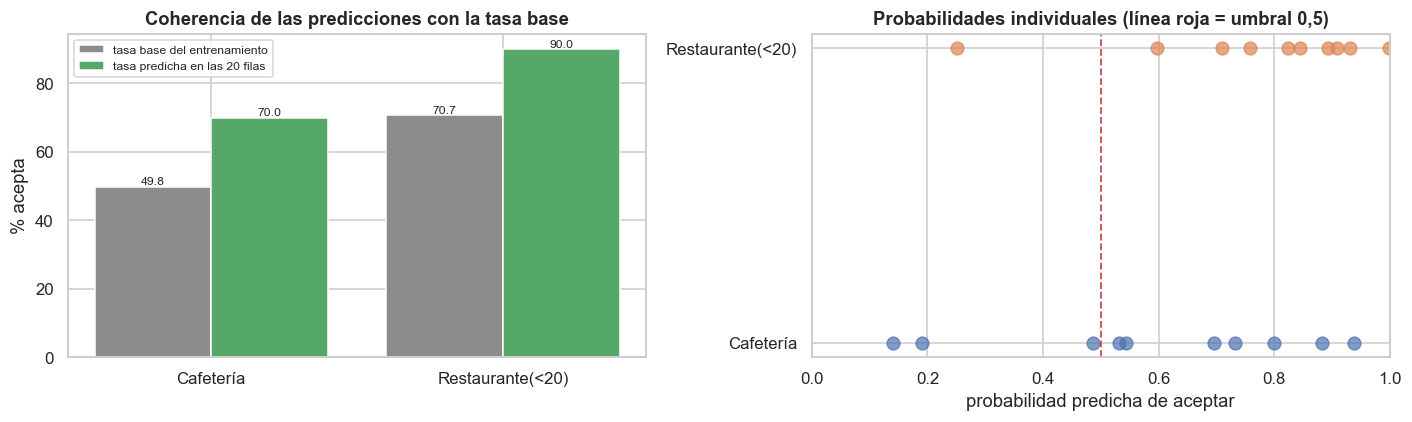

Casos con probabilidad entre 0,40 y 0,60 (decisión poco firme): 4 de 20


,cupon,acepta_cupon,probabilidad_Si
indice_original,,,
0,Cafetería,Sí,0.544
14,Cafetería,Sí,0.532
17,Cafetería,No,0.486
18,Restaurante(<20),Sí,0.598


In [47]:
# ---- Verificación de sensatez: la tasa predicha frente a la tasa base ----
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

res = predicciones.groupby('cupon').acepta_cupon.apply(lambda s: (s == 'Sí').mean()*100)
base = {c: DATOS[c]['y'].mean()*100 for c in CUPONES}
x = np.arange(len(CUPONES))
ax[0].bar(x-0.2, [base[c] for c in CUPONES], 0.4, label='tasa base del entrenamiento', color='#8c8c8c')
ax[0].bar(x+0.2, [res[c] for c in CUPONES], 0.4, label='tasa predicha en las 20 filas', color='#55a868')
ax[0].set_xticks(x); ax[0].set_xticklabels(CUPONES); ax[0].set_ylabel('% acepta')
ax[0].legend(fontsize=8); ax[0].set_title('Coherencia de las predicciones con la tasa base')
for i, c in enumerate(CUPONES):
    ax[0].text(i-0.2, base[c], f'{base[c]:.1f}', ha='center', va='bottom', fontsize=8)
    ax[0].text(i+0.2, res[c],  f'{res[c]:.1f}',  ha='center', va='bottom', fontsize=8)

for c, color in zip(CUPONES, ['#4c72b0', '#dd8452']):
    p = predicciones[predicciones.cupon == c].probabilidad_Si
    ax[1].scatter(p, [c]*len(p), s=70, alpha=.7, color=color)
ax[1].axvline(0.5, color='r', ls='--', lw=1.2)
ax[1].set_xlim(0, 1); ax[1].set_xlabel('probabilidad predicha de aceptar')
ax[1].set_title('Probabilidades individuales (línea roja = umbral 0,5)')
plt.show()

cerca = predicciones[(predicciones.probabilidad_Si.between(0.40, 0.60))]
print(f'Casos con probabilidad entre 0,40 y 0,60 (decisión poco firme): {len(cerca)} de 20')
if len(cerca):
    display(cerca)

In [48]:
# ============================================================
# Exportación del archivo de entrega
# Se toma como base el archivo original y se le añade la columna de predicción,
# conservando las 20 filas en su orden original y todas sus columnas.
# ============================================================
salida = prueba_raw.copy()
salida['acepta_cupon'] = predicciones['acepta_cupon'].reindex(salida.index)
salida['probabilidad_Si'] = predicciones['probabilidad_Si'].reindex(salida.index)

# El CSV lleva el nombre exacto que pide la rúbrica. La copia en Excel usa un nombre
# distinto del archivo de entrada para NO sobrescribirlo nunca.
ruta_csv  = 'Lab3_datos_Prueba.csv'
ruta_xlsx = 'Lab3_datos_Prueba_con_predicciones.xlsx'

entrada = os.path.abspath(os.path.join(DATA, 'Lab3_datos_Prueba.xlsx'))
for destino in (ruta_csv, ruta_xlsx):
    assert os.path.abspath(destino) != entrada, \
        f'La salida {destino} sobrescribiría el archivo de entrada'

salida.to_csv(ruta_csv, index=False, encoding='utf-8-sig')      # BOM: tildes correctas en Excel
salida.to_excel(ruta_xlsx, index=False)

# ---- Verificación del archivo escrito ----
control = pd.read_csv(ruta_csv, encoding='utf-8-sig')
print(f'Archivo escrito : {ruta_csv}')
print(f'Filas           : {len(control)}  (el original tiene {len(prueba_raw)})')
print(f'Columnas        : {control.shape[1]}  '
      f'(original {prueba_raw.shape[1]} + acepta_cupon + probabilidad_Si)')
print(f'Nulos en la predicción         : {control.acepta_cupon.isna().sum()}')
print(f'Orden de filas preservado      : {bool((control.cupon == prueba_raw.cupon).all())}')
print(f'Columnas originales intactas   : '
      f'{bool(set(prueba_raw.columns).issubset(control.columns))}')
print(f'Valores de la predicción       : {control.acepta_cupon.value_counts().to_dict()}')
display(control[['cupon', 'destino', 'hora', 'genero', 'edad',
                 'acepta_cupon', 'probabilidad_Si']])

Archivo escrito : Lab3_datos_Prueba.csv
Filas           : 20  (el original tiene 20)
Columnas        : 27  (original 25 + acepta_cupon + probabilidad_Si)
Nulos en la predicción         : 0
Orden de filas preservado      : True
Columnas originales intactas   : True
Valores de la predicción       : {'Sí': 16, 'No': 4}


,cupon,destino,hora,genero,edad,acepta_cupon,probabilidad_Si
0,Cafetería,Trabajo,7:00 a.m.,Femenino,50 o más,Sí,0.544
1,Cafetería,Sin lugar urgente,10:00 a.m.,Femenino,31,Sí,0.800
2,Cafetería,Sin lugar urgente,2:00 p.m.,Femenino,31,Sí,0.882
3,Cafetería,Sin lugar urgente,10:00 a.m.,Masculino,50 o más,Sí,0.938
4,Restaurante(<20),Sin lugar urgente,6:00 p.m.,Femenino,26,Sí,0.894
5,Restaurante(<20),Sin lugar urgente,2:00 p.m.,Masculino,26,Sí,0.932
6,Restaurante(<20),Sin lugar urgente,2:00 p.m.,Femenino,36,No,0.252
7,Restaurante(<20),Sin lugar urgente,6:00 p.m.,Femenino,46,Sí,0.758
8,Restaurante(<20),Sin lugar urgente,2:00 p.m.,Femenino,31,Sí,0.908
9,Cafetería,Casa,6:00 p.m.,Femenino,50 o más,No,0.190


> **Nota sobre la entrega.** El archivo se escribe como **`Lab3_datos_Prueba.csv`**, el nombre exacto
> que pide la rúbrica. Conserva las **20 filas en su orden original** y las 25 columnas de partida, más
> `acepta_cupon` con la predicción. Se incluye también `probabilidad_Si` porque es la salida que de
> verdad usaría la aplicación (ver 10.6); si la calificación automática exige exactamente las columnas
> originales más la etiqueta, basta con eliminar esa última columna.
>
> La copia en Excel se guarda como `Lab3_datos_Prueba_con_predicciones.xlsx`, con un nombre
> deliberadamente distinto del archivo de entrada: una celda de aserción verifica que ninguna ruta de
> salida coincida con la de entrada, para que ejecutar el notebook **nunca** sobrescriba los datos
> originales. El CSV usa codificación `utf-8-sig` para que Excel muestre correctamente las tildes y el
> valor `Sí`.

<a name="s12"></a>
## 12. Uso de herramientas de IA generativa

*Sección obligatoria según los principios del curso ISIS-2611 publicados en Bloque Neón.*

### 12.1 Declaración del uso

| Herramienta | Tipo de uso |
|:---|:---|
| Claude (Anthropic), mediante Claude Code en VS Code | Generación inicial del esqueleto del notebook (estructura de secciones y celdas con `# TODO`), ayuda conceptual (SMOTE/SMOTENC, importancia por permutación frente a impureza), depuración de código y revisión de la redacción técnica. |

### 12.2 Prompts utilizados

1. **Prompt para generar el esqueleto del notebook** (textual):

> Actúa como un experto en Data Science y Machine Learning. Necesito que generes ÚNICAMENTE un archivo de Jupyter Notebook (.ipynb) que sirva como esqueleto/plantilla estructurada para resolver el "Laboratorio 3 - La tarea de clasificación" del curso ISIS2611.
>
> INSTRUCCIONES CLAVE DE FORMATO Y CONTENIDO:
> 1. NO escribas código funcional completo para el entrenamiento o análisis; genera el ESQUELETO DEL NOTEBOOK con celdas de Markdown explicativas y celdas de código con el boilerplate, librerías importadas, nombres de funciones, comentarios `# TODO:` y la estructura paso a paso para completar el laboratorio.
> 2. Organiza el Notebook en secciones claras con títulos en Markdown (`#`, `##`, `###`) siguiendo estrictamente la rúbrica y las actividades del enunciado.
> 3. Asegúrate de separar todo en los dos subconjuntos requeridos cuando corresponda: "Cafetería" y "Restaurante(<20)".
>
> ESTRUCTURA DEL NOTEBOOK A GENERAR: encabezado con integrantes; 1. Configuración del entorno e importación de librerías; 2. Carga y exploración de datos (EDA); 3. Limpieza y preparación (pipelines de preprocesamiento, división train/test); 4. Modelamiento por cupón (4.1 Regresión logística con `GridSearchCV` sobre `penalty` y `solver`; 4.2 Árboles de decisión sobre `max_depth`, `min_samples_leaf` y `criterion`; 4.3 Random Forest sobre `n_estimators`, `max_depth` y `min_samples_leaf`); 5. Evaluación de balanceo de clases (SMOTE) en Restaurante(<20) con `imblearn.pipeline.Pipeline`, comparando F1 general y recall de la clase minoritaria; 6. Comparativa de modelos y selección; 7. Importancia de variables y reglas de decisión; 8. Predicciones sobre `Lab3_datos_Prueba.csv` y exportación a CSV; 9. Análisis de resultados con las ocho preguntas del enunciado; 10. Declaración de uso de IA generativa (declaración, prompts, análisis crítico, aportes propios). Genera directamente el archivo `.ipynb` limpio y bien estructurado en el directorio actual.

2. *(Resumido)* Solicitud de **revisar el notebook completo frente al enunciado y la rúbrica**, confirmando que existan las 12 secciones, las ocho preguntas de análisis y la sección de IA, y de completar los nombres de los integrantes y esta sección.
3. *(Resumido)* Consultas conceptuales puntuales: diferencia entre SMOTE y SMOTENC con variables categóricas, y por qué la importancia por impureza (`feature_importances_`) sobrestima variables de alta cardinalidad.

### 12.3 Análisis crítico del resultado

* **¿Qué partes del contenido generado fueron correctas y útiles?**
  El esqueleto organizó el trabajo en el orden de la rúbrica y recordó los requisitos fáciles de olvidar: separar todo por cupón, usar `Pipeline` con `GridSearchCV` en los tres algoritmos y reportar el recall de la clase minoritaria además del F1. La explicación de por qué se debe aplicar el balanceo dentro del `Pipeline` (solo sobre los pliegues de entrenamiento) evitó una fuga de información.
* **¿Qué errores, imprecisiones o limitaciones se identificaron?**
  El esqueleto asumía que la clase minoritaria era `Sí`; al explorar los datos vimos que en Restaurante(<20) el 70,7 % son `Sí`, de modo que **la minoritaria es `No`**. Además propone SMOTE a secas, que no admite variables categóricas sin codificar; fue necesario SMOTENC. Tampoco advirtió que `GridSearchCV` con `scoring='f1'` puede elegir un modelo casi trivial cuando hay desbalance.
* **¿Qué decisiones técnicas fueron modificadas respecto a la respuesta de la IAG y por qué?**
  Reemplazamos SMOTE por SMOTENC y comparamos además una variante parcial y `class_weight='balanced'`; añadimos la importancia por permutación porque la de impureza sobrestima `ocupacion` (25 categorías); y usamos la clase `No` como minoritaria al reportar el recall. Mantuvimos una partición estratificada 75/25 con `random_state=42`.
* **¿Qué conceptos del curso permitieron evaluar o mejorar la respuesta generada?**
  Fuga de información en el preprocesamiento y el balanceo, validación cruzada estratificada, métricas ante clases desbalanceadas (recall, F1, AUC, línea base del clasificador trivial), sobreajuste de los árboles y sesgo/equidad al usar variables demográficas.

### 12.4 Aportes propios del estudiante

* **¿Qué fue desarrollado, modificado o decidido por el estudiante?**
  La exploración y los hallazgos H1–H9, las decisiones de limpieza (eliminar `vehiculo`, tratar duplicados y etiquetas contradictorias, redundancias), la elección de las rejillas de hiperparámetros, la selección del mejor modelo por cupón, la recomendación sobre el balanceo, la auditoría de variables demográficas y las respuestas de la sección 10.
* **¿Qué ajustes se realizaron sobre el código o la explicación original?**
  Se completó el esqueleto con código funcional, se corrigieron los supuestos sobre la clase minoritaria y el tipo de SMOTE, se agregaron comparaciones propias (línea base trivial, permutación frente a impureza, ablación de variables demográficas) y se verificó que cada celda se ejecute con su salida visible.
* **¿Qué aprendizajes se obtuvieron del proceso?**
  Que un F1 alto puede deberse solo a la tasa base de la clase mayoritaria, que el balanceo reubica el umbral más que mejorar la discriminación, que la importancia por impureza puede inducir conclusiones erróneas y que la personalización con datos demográficos implica un intercambio entre desempeño y equidad que debe decidir el negocio, no el modelo.

---

## Conclusiones

1. **Random Forest es el mejor modelo en los dos cupones**, de forma consistente en F1 sobre prueba,
   ROC AUC y F1 por validación cruzada: 0,7876 de F1 y 0,8573 de AUC en Cafetería; 0,8531 y 0,8004 en
   Restaurante(<20). La ventaja viene de capturar interacciones entre contexto y perfil que la
   regresión logística, aditiva en el *log-odds*, no puede representar.

2. **Comparar el F1 entre cupones lleva a la conclusión contraria a la correcta.** El F1 es más alto en
   Restaurante(<20) (0,8531 frente a 0,7876) solo porque su tasa base es del 70,7 %: el clasificador
   trivial "siempre Sí" ya obtiene 0,8284 allí. Medido como ganancia sobre ese trivial, **el modelo de
   Cafetería aporta cinco veces más** (+0,1223 frente a +0,0247).

3. **Cada cupón se predice con un tipo de variable distinto.** En Cafetería manda el hábito
   (`frecuencia_cafeteria`, 4,5 veces más importante que la segunda variable); en Restaurante(<20)
   manda el contexto del trayecto (vigencia, distancia, hora, clima), y el hábito equivalente
   **no predice**. Son dos estrategias comerciales distintas, no una sola parametrizada.

4. **El balanceo mejora lo que debe mejorar, con un matiz.** SMOTENC sube el recall de la clase
   minoritaria de 0,4532 a 0,5172 (+14 % relativo); la variante parcial (0,6) consigue el mejor F1
   macro (0,7109) sin sacrificar F1 en la clase positiva. Pero el ROC AUC apenas se mueve
   (0,7978–0,8020), lo que demuestra que el balanceo **reubica el umbral** en lugar de mejorar la
   capacidad de discriminación: ajustar el umbral del modelo sin balancear logra lo mismo sin datos
   sintéticos. `class_weight='balanced'` da la mejor métrica superficial y **no mueve el recall de la
   minoritaria**.

5. **La métrica de optimización determinó el modelo, no solo su evaluación.** Elegir `scoring='f1'`
   llevó a `GridSearchCV` a seleccionar, en Restaurante(<20), una logística con 3 coeficientes de 49 y
   AUC de 0,6747: un modelo casi trivial que puntúa bien porque la clase mayoritaria es frecuente.

6. **La importancia por impureza habría producido una conclusión equivocada.** Señala `ocupacion` como
   la variable más determinante (15,07 % y 15,44 %) por un artefacto de su cardinalidad de 25
   categorías; la permutación la sitúa muy por debajo. Una política de segmentación por ocupación
   basada en `feature_importances_` no tendría fundamento real.

7. **La demografía plantea un dilema real, y lo cuantificamos en lugar de esquivarlo.** Eliminar
   `genero` es **gratis** (−0,002 de F1 en Cafetería, +0,004 en Restaurante(<20)): un atributo
   protegido que no aporta nada medible, y la recomendación de aplicación inmediata. Pero eliminar
   **todas** las variables demográficas cuesta **9,3 puntos de F1 y 11,7 de AUC en Cafetería**, porque
   `ocupacion` e `ingreso` llevan señal auténtica allí. No es cierto que lo ético salga gratis: hay un
   intercambio, y resolverlo corresponde al negocio y al cumplimiento normativo, no al modelo. La
   auditoría de equidad añade un argumento concreto: en Restaurante(<20) el modelo **sobrestima la
   aceptación más en los tramos de ingreso bajo** (+0,187 frente a −0,011 en el tramo más alto), de
   modo que la molestia por notificaciones irrelevantes se concentraría en los usuarios de menor
   ingreso. La salida que disuelve el dilema es **sustituir los hábitos autodeclarados por
   comportamiento observado en la app**.

8. **Hay un techo de desempeño que no se puede superar.** Las 23 combinaciones con etiquetas
   contradictorias demuestran que conductores idénticos ante escenarios idénticos deciden distinto.
   Además, los datos provienen de una encuesta con escenarios **hipotéticos** y hábitos
   **autodeclarados**: el modelo predice respuestas a una encuesta, no conductas al volante. Es la
   limitación más importante a comunicar antes de cualquier despliegue.